# Statistical Analysis and Inferential Modeling of Global Listed Companies' Market Capitalization Data

**Name:** Aayush Khiratkar  **Section:** B1-B2  **Roll No.:** 25

## Project Overview

**Question:** What is related to the market capitalization of the world's largest listed companies: company size, country or sector?

**Contents**
- **Part A:** data collection, cleaning, descriptive statistics, probability distributions, sampling, Central Limit Theorem, simple linear regression
- **Part B:** lab practicals applied to the same data: Practical 5, 5-II, 6, 6 B&C, 7, 8-B, 8-C
- **Part C:** key findings and limitations
- **Part D:** an interactive Streamlit dashboard that compares all the models and shows the best one

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import joblib
from IPython.display import display

from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr, kstest, shapiro
import statsmodels.api as sm
from statsmodels.formula.api import ols

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score, r2_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

np.random.seed(42)      # same random numbers on every run
alpha = 0.05            # significance level used in every hypothesis test

## Data Collection (Web/API Scraping)

We pull live data (market cap, revenue, country, sector, employees) for about 120 large listed companies from the US, Europe, Canada, Asia, Latin America, Australia and Israel, using the `yfinance` API. This is the same "hit an API in a loop, collect the data, build a DataFrame" pattern as scraping a paginated site.

The pull takes a minute or two. Revenue comes in each company's own currency (yen, yuan, rupees...), so it is converted to USD below.

In [3]:
# Quick connectivity check (mirrors testing the endpoint before looping)
test = yf.Ticker("AAPL").info
print("Test ticker fetched:", test.get("longName"))
print("Sample field - marketCap:", test.get("marketCap"))

Test ticker fetched: Apple Inc.
Sample field - marketCap: 5092055449600


In [4]:
tickers = [
    # United States
    "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "BRK-B", "JPM", "V",
    "JNJ", "WMT", "PG", "XOM", "HD", "MA", "CVX", "KO", "PEP", "COST",
    "UNH", "BAC", "DIS", "ADBE", "CRM", "NFLX", "INTC", "CSCO", "PFE", "ABT",
    "ORCL", "AVGO", "LLY", "MRK", "ABBV", "MCD", "TMO", "QCOM", "AMD", "IBM",
    "GS", "MS", "WFC", "T", "VZ", "NKE", "LOW", "CAT", "GE", "HON",
    "UPS", "BA", "LMT", "AMGN", "MDT", "SBUX", "PM", "TXN", "LIN",
    # Taiwan / Japan / Korea
    "TSM", "UMC", "CHT", "SONY", "TM", "HMC", "MUFG", "SMFG", "KB",
    # Europe
    "SAP", "ASML", "NVO", "SHEL", "AZN", "NVS", "SIEGY", "UL", "BP", "GSK",
    "HSBC", "DEO", "SNY", "TTE", "ING", "BTI", "BUD", "ERIC", "NOK", "PHG", "RELX", "STM",
    # Canada
    "RY", "TD", "SHOP", "ENB", "CNQ", "BMO", "BNS", "CNI", "SU",
    # China
    "BABA", "TCEHY", "PDD", "JD", "BIDU", "NTES", "LI", "YUMC",
    # India (ADRs - more reliable via Yahoo than .NS tickers)
    "INFY", "HDB", "IBN", "WIT", "RDY",
    # Latin America, Australia, Israel
    "VALE", "PBR", "ITUB", "NU", "MELI", "BBD", "ABEV", "BHP", "TEVA", "CHKP", "NICE",
]
print("Tickers requested:", len(tickers))

Tickers requested: 123


In [5]:
records = []
for t in tickers:
    try:
        info = yf.Ticker(t).info
        market_cap = info.get("marketCap")
        revenue = info.get("totalRevenue")
        country = info.get("country")
        sector = info.get("sector")
        name = info.get("longName", t)
        employees = info.get("fullTimeEmployees")
        if market_cap and revenue:
            records.append({
                "Ticker": t,
                "Company": name,
                "Country": country if country else "Unknown",
                "Sector": sector if sector else "Unknown",
                "MarketCap": market_cap,
                "Revenue": revenue,
                "Employees": employees,
                "CapCurrency": info.get("currency") or "USD",
                "RevCurrency": info.get("financialCurrency") or "USD",
            })
    except Exception as e:
        print(f"Skipped {t}: {e}")
        continue

print("Total companies collected:", len(records))

Total companies collected: 120


In [6]:
df = pd.DataFrame(records)
assert len(df) >= 15, "Yahoo returned too little data. Wait a minute and run the previous cell again."
df.to_csv("market_cap_raw.csv", index=False)      # backup of the raw pull

# Yahoo gives Revenue in the company's own currency and Market Cap in the trading currency.
# Convert both to USD, otherwise revenue cannot be compared between companies.
fallback_rates = {"JPY": 150, "TWD": 31, "EUR": 0.92, "DKK": 6.9, "CNY": 7.2, "INR": 84, "CAD": 1.38,
                  "GBP": 0.78, "CHF": 0.88, "KRW": 1400, "BRL": 5.5, "SEK": 10.5, "AUD": 1.5,
                  "ILS": 3.7, "MXN": 19, "HKD": 7.8, "NOK": 10.7}      # rough values, used only if Yahoo fails

usd_rate = {"USD": 1.0}                                                # local currency per 1 USD
for cur in set(df["CapCurrency"]) | set(df["RevCurrency"]):
    if cur != "USD":
        try:
            usd_rate[cur] = yf.Ticker(cur + "=X").history(period="5d")["Close"].iloc[-1]
        except Exception:
            usd_rate[cur] = fallback_rates[cur]
            print("Using a rough fallback exchange rate for", cur)
print("Exchange rates (local currency per 1 USD):", {c: round(float(r), 3) for c, r in usd_rate.items()})

# USD billions
df["MarketCap_B"] = df["MarketCap"] / df["CapCurrency"].map(usd_rate) / 1e9
df["Revenue_B"] = df["Revenue"] / df["RevCurrency"].map(usd_rate) / 1e9

Exchange rates (local currency per 1 USD): {'USD': 1.0, 'CNY': 6.659, 'INR': 95.253, 'JPY': 157.485, 'EUR': 0.894, 'TWD': 32.622, 'BRL': 5.36, 'DKK': 6.681, 'CAD': 1.397, 'KRW': 1336.8, 'GBP': 0.747}


In [7]:
# Sanity check: after conversion no company here should have revenue above about US$1 trillion
print(df.nlargest(5, "Revenue_B")[["Company", "Revenue_B"]])
if df["Revenue_B"].max() > 1500:
    print("WARNING: revenue still looks like local currency. Check the exchange rates above.")

print("\nMissing values per column:")
print(df.isnull().sum())
print("Duplicate tickers:", df.duplicated("Ticker").sum())

                            Company   Revenue_B
3                  Amazon.com, Inc.  775.680033
10                     Walmart Inc.  735.839977
0                        Apple Inc.  466.822988
19  UnitedHealth Group Incorporated  450.059010
2                     Alphabet Inc.  445.865984

Missing values per column:
Ticker         0
Company        0
Country        0
Sector         0
MarketCap      0
Revenue        0
Employees      4
CapCurrency    0
RevCurrency    0
MarketCap_B    0
Revenue_B      0
dtype: int64
Duplicate tickers: 0


In [8]:
# Apply a color gradient to the 'MarketCap_B' column
df.head(10).style.background_gradient(cmap='Blues', subset=['MarketCap_B'])

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B
0,AAPL,Apple Inc.,United States,Technology,5092055449600,466822987776,150000.000000,USD,USD,5092.055450,466.822988
1,MSFT,Microsoft Corporation,United States,Technology,3936578961408,331839012864,223000.000000,USD,USD,3936.578961,331.839013
2,GOOGL,Alphabet Inc.,United States,Communication Services,3471100346368,445865984000,198933.000000,USD,USD,3471.100346,445.865984
3,AMZN,"Amazon.com, Inc.",United States,Consumer Cyclical,2629595299840,775680032768,1595000.000000,USD,USD,2629.595300,775.680033
4,NVDA,NVIDIA Corporation,United States,Technology,5159248199680,302970011648,42000.000000,USD,USD,5159.248200,302.970012
5,META,"Meta Platforms, Inc.",United States,Communication Services,1596793421824,241605001216,66775.000000,USD,USD,1596.793422,241.605001
6,TSLA,"Tesla, Inc.",United States,Consumer Cyclical,1594136068096,103569997824,134785.000000,USD,USD,1594.136068,103.569998
7,BRK-B,Berkshire Hathaway Inc.,United States,Financial Services,1160179089408,384687013888,387800.000000,USD,USD,1160.179089,384.687014
8,JPM,JPMorgan Chase & Co.,United States,Financial Services,912411066368,190732992512,322964.000000,USD,USD,912.411066,190.732993
9,JNJ,Johnson & Johnson,United States,Healthcare,662491824128,99334995968,138200.000000,USD,USD,662.491824,99.334996


#### `df.info()`

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Ticker       120 non-null    object 
 1   Company      120 non-null    object 
 2   Country      120 non-null    object 
 3   Sector       120 non-null    object 
 4   MarketCap    120 non-null    int64  
 5   Revenue      120 non-null    int64  
 6   Employees    116 non-null    float64
 7   CapCurrency  120 non-null    object 
 8   RevCurrency  120 non-null    object 
 9   MarketCap_B  120 non-null    float64
 10  Revenue_B    120 non-null    float64
dtypes: float64(3), int64(2), object(6)
memory usage: 10.4+ KB


In [10]:
df.shape

(120, 11)

#### `df.describe()`

In [11]:
df.describe()

,MarketCap,Revenue,Employees,MarketCap_B,Revenue_B
count,1.200000e+02,1.200000e+02,1.160000e+02,120.000000,120.000000
mean,4.445151e+11,1.198554e+12,1.532037e+05,444.515125,98.961866
std,8.606630e+11,5.509721e+12,2.600436e+05,860.663050,131.134794
min,6.738090e+09,2.764400e+09,6.825000e+03,6.738090,2.764400
25%,9.152432e+10,4.267975e+10,4.679525e+04,91.524323,28.082916
50%,1.861759e+11,7.939100e+10,8.445000e+04,186.175906,53.653742
75%,3.346716e+11,2.424356e+11,1.432500e+05,334.671618,98.396002
max,5.159248e+12,5.195702e+13,2.100000e+06,5159.248200,775.680033


In [12]:
df.to_csv("market_cap_data.csv", index=False)
print("market_cap_data.csv created successfully!")

# Download only works inside Google Colab; skip quietly elsewhere
try:
    from google.colab import files
    files.download("market_cap_data.csv")
except ImportError:
    print("Not running in Colab - CSV saved locally only.")

market_cap_data.csv created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### New columns used later
- `Region`: US or Non-US
- `PS_Ratio`: market cap / revenue ("price-to-sales")
- `log_...` columns: log10 of market cap, revenue and employees (the data is heavily right-skewed)
- `Cap_Tier`: Low / Medium / High, equal thirds by market cap
- `Sector_Group`: sectors with at least 5 companies keep their name, smaller ones become "Other"

In [13]:
df["Region"] = np.where(df["Country"] == "United States", "US", "Non-US")
df["PS_Ratio"] = df["MarketCap_B"] / df["Revenue_B"]
df["log_MarketCap"] = np.log10(df["MarketCap_B"])
df["log_Revenue"] = np.log10(df["Revenue_B"])
df["Employees"] = pd.to_numeric(df["Employees"], errors="coerce")
df["log_Employees"] = np.log10(df["Employees"])          # stays NaN where Employees is missing
df["Cap_Tier"] = pd.qcut(df["MarketCap_B"], q=3, labels=["Low", "Medium", "High"])

sector_counts = df["Sector"].value_counts()
df["Sector_Group"] = df["Sector"].where(df["Sector"].map(sector_counts) >= 5, "Other")

print(df["Region"].value_counts())
print(df["Sector_Group"].value_counts())

Region
Non-US    64
US        56
Name: count, dtype: int64
Sector_Group
Technology                25
Financial Services        21
Healthcare                17
Consumer Cyclical         15
Consumer Defensive        11
Communication Services    10
Energy                     9
Industrials                9
Other                      3
Name: count, dtype: int64


## Descriptive Statistics & Visualization

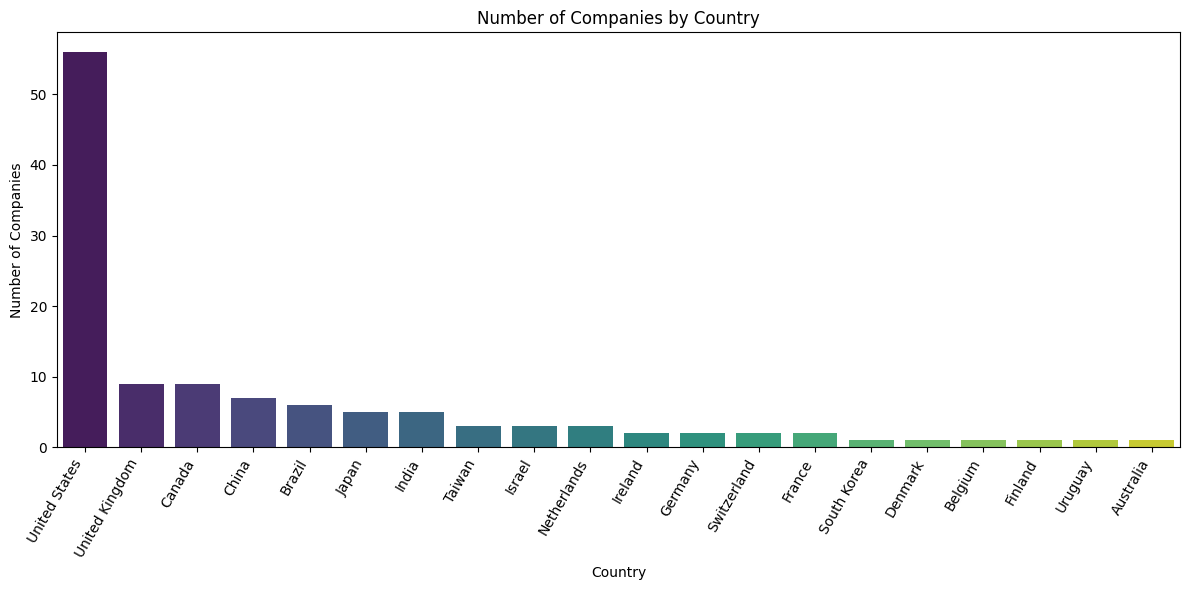

In [14]:
country_count = df["Country"].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=country_count.index, y=country_count.values, hue=country_count.index, palette="viridis", legend=False)
plt.xlabel("Country")
plt.ylabel("Number of Companies")
plt.title("Number of Companies by Country")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

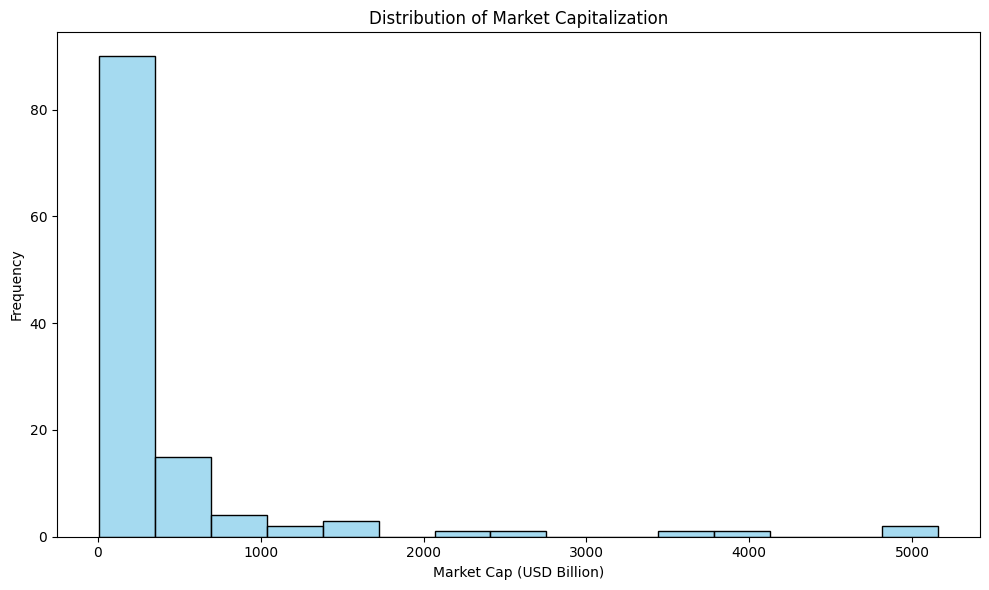

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(df["MarketCap_B"], bins=15, kde=False, edgecolor="black", color="skyblue")
plt.xlabel("Market Cap (USD Billion)")
plt.ylabel("Frequency")
plt.title("Distribution of Market Capitalization")
plt.tight_layout()
plt.show()

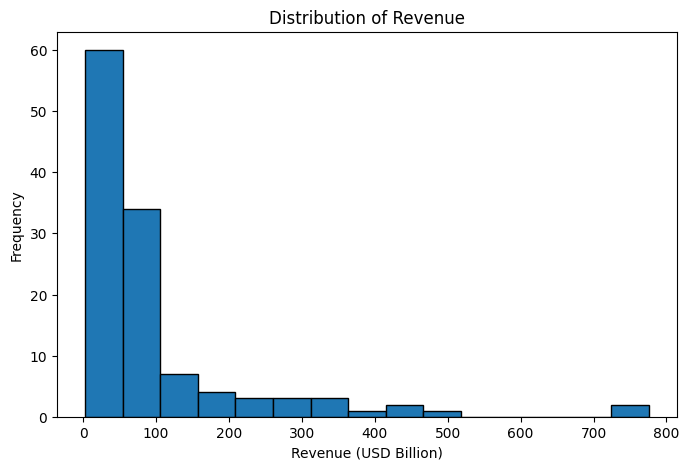

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df["Revenue_B"], bins=15, edgecolor="black")
plt.xlabel("Revenue (USD Billion)")
plt.ylabel("Frequency")
plt.title("Distribution of Revenue")
plt.show()

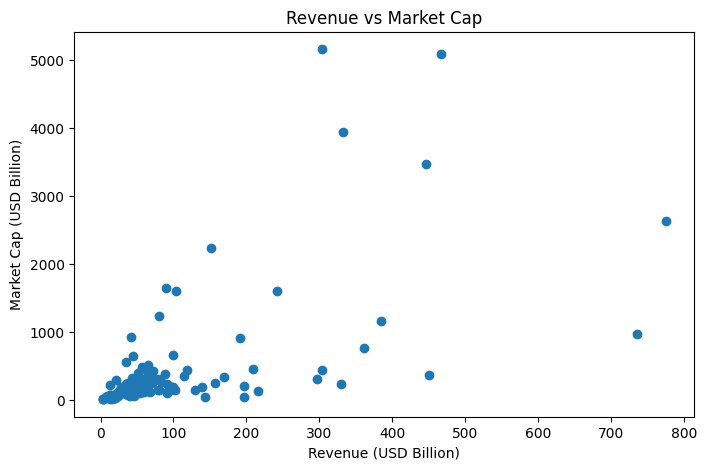

             Revenue_B  MarketCap_B
Revenue_B     1.000000     0.602778
MarketCap_B   0.602778     1.000000


In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Revenue_B"], df["MarketCap_B"])
plt.xlabel("Revenue (USD Billion)")
plt.ylabel("Market Cap (USD Billion)")
plt.title("Revenue vs Market Cap")
plt.show()

correlation = df[["Revenue_B", "MarketCap_B"]].corr()
print(correlation)

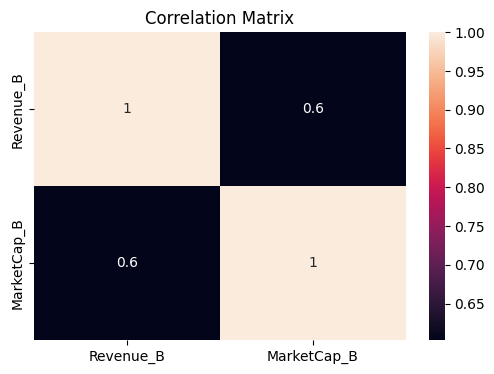

In [18]:
plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True)
plt.title("Correlation Matrix")
plt.show()

Market cap and revenue are both heavily right-skewed, so Pearson correlation on raw values is dominated by a handful of giants. We also check it on a log scale and with a rank (Spearman) correlation.

In [19]:
print("Pearson  (raw values):", round(df["Revenue_B"].corr(df["MarketCap_B"]), 3))
print("Pearson  (log10)     :", round(df["log_Revenue"].corr(df["log_MarketCap"]), 3))
print("Spearman (ranks)     :", round(df["Revenue_B"].corr(df["MarketCap_B"], method="spearman"), 3))
print("Skewness of MarketCap_B:", round(df["MarketCap_B"].skew(), 2))

Pearson  (raw values): 0.603
Pearson  (log10)     : 0.753
Spearman (ranks)     : 0.699
Skewness of MarketCap_B: 3.95


### Largest companies, market cap by sector, and valuation

In [20]:
# Top 10 companies by market cap
print(df.nlargest(10, "MarketCap_B")[["Company", "Country", "Sector", "MarketCap_B", "Revenue_B"]].round(1))

# Share of the total market cap held by the top 5 companies
top5_share = df.nlargest(5, "MarketCap_B")["MarketCap_B"].sum() / df["MarketCap_B"].sum()
print("\nTop 5 companies hold", round(top5_share * 100), "% of the total market cap in this sample")

                                              Company        Country  \
4                                  NVIDIA Corporation  United States   
0                                          Apple Inc.  United States   
1                               Microsoft Corporation  United States   
2                                       Alphabet Inc.  United States   
3                                    Amazon.com, Inc.  United States   
58  Taiwan Semiconductor Manufacturing Company Lim...         Taiwan   
30                                      Broadcom Inc.  United States   
5                                Meta Platforms, Inc.  United States   
6                                         Tesla, Inc.  United States   
31                              Eli Lilly and Company  United States   

                    Sector  MarketCap_B  Revenue_B  
4               Technology       5159.2      303.0  
0               Technology       5092.1      466.8  
1               Technology       3936.6      331

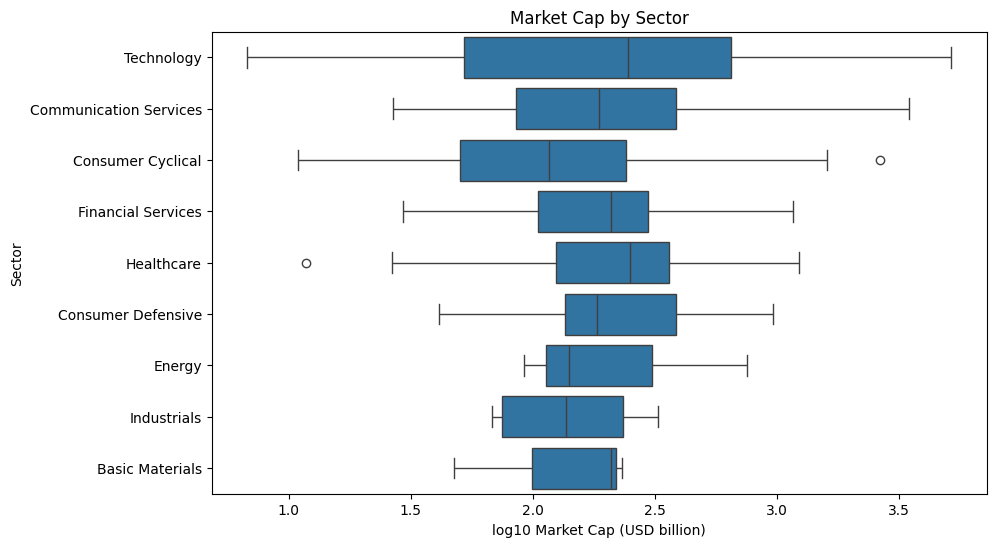

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, y="Sector", x="log_MarketCap")
plt.xlabel("log10 Market Cap (USD billion)")
plt.title("Market Cap by Sector")
plt.show()

In [22]:
# Price-to-sales = market cap / revenue: how much the market pays for each dollar of sales
print(df.groupby("Sector")["PS_Ratio"].median().sort_values(ascending=False).round(2))

Sector
Technology                5.89
Financial Services        4.38
Communication Services    3.90
Healthcare                3.75
Basic Materials           3.54
Industrials               2.58
Consumer Defensive        2.50
Energy                    1.84
Consumer Cyclical         1.58
Name: PS_Ratio, dtype: float64


## Probability Distributions

Simulated theoretical distributions parameterized from the observed Market Cap data, same approach as fitting Uniform / Normal / Binomial / Poisson shapes against a real variable.

In [23]:
uniform_data = np.random.uniform(
    df["MarketCap_B"].min(),
    df["MarketCap_B"].max(),
    1000
)

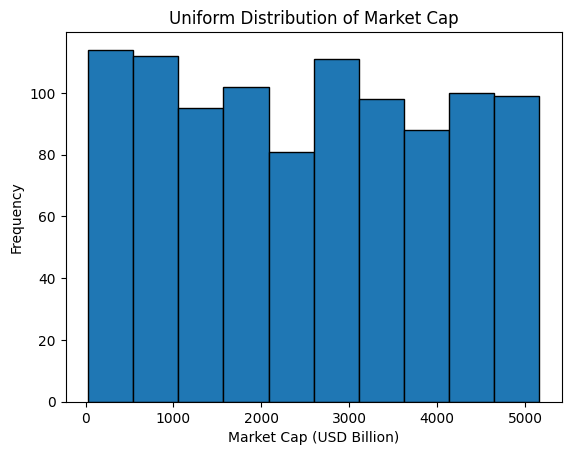

In [24]:
plt.hist(uniform_data, bins=10, edgecolor="black")
plt.xlabel("Market Cap (USD Billion)")
plt.ylabel("Frequency")
plt.title("Uniform Distribution of Market Cap")
plt.show()

In [25]:
print("Mean:", np.mean(uniform_data))
print("Variance:", np.var(uniform_data))

Mean: 2532.7899375716934
Variance: 2263483.847565829


In [26]:
lo, hi = df["MarketCap_B"].min(), df["MarketCap_B"].max()
print("Theoretical Uniform mean:", (lo + hi) / 2, "| variance:", (hi - lo) ** 2 / 12)
print("Actual data mean:        ", df["MarketCap_B"].mean(), "| variance:", df["MarketCap_B"].var())

stat, p = kstest(df["MarketCap_B"], "uniform", args=(lo, hi - lo))
print(f"KS test vs Uniform: statistic={stat:.3f}, p-value={p:.4g}")

Theoretical Uniform mean: 2582.993145088 | variance: 2212363.368770276
Actual data mean:         444.51512487680003 | variance: 740740.8855769746
KS test vs Uniform: statistic=0.752, p-value=1.048e-70


**Reading this:** the uniform simulation is only a demonstration of the distribution. The KS test above checks whether the real market caps are actually uniform. A tiny p-value means they are not (most companies are small and a few are huge).

**Normal vs Log-normal.** Raw market cap is right-skewed and always positive. A Normal(mean, std) fit on raw values is wrong for it: with this mean and std it generates impossible negative market caps. Market caps are better described by a **log-normal** distribution, i.e. the *log* of market cap is roughly Normal.

In [27]:
log_mc = np.log(df["MarketCap_B"])
mu, sigma = log_mc.mean(), log_mc.std()

print("Skewness  raw:", round(df["MarketCap_B"].skew(), 2), "| log:", round(log_mc.skew(), 2))
print("Shapiro-Wilk p-value  raw:", shapiro(df["MarketCap_B"]).pvalue, "| log:", shapiro(log_mc).pvalue)

normal_data = np.random.normal(mu, sigma, 1000)   # Normal on the log scale
lognormal_data = np.exp(normal_data)               # back to USD billions
print("Negative values in simulated log-normal data:", (lognormal_data < 0).sum())

Skewness  raw: 3.95 | log: 0.2
Shapiro-Wilk p-value  raw: 6.066454947536423e-19 | log: 0.14636376197132717
Negative values in simulated log-normal data: 0


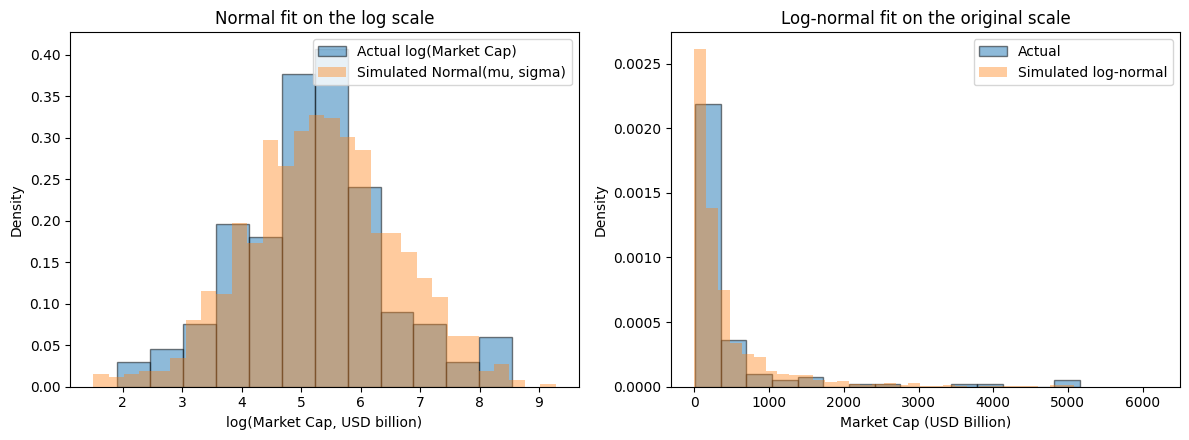

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(log_mc, bins=12, density=True, alpha=0.5, edgecolor="black", label="Actual log(Market Cap)")
axes[0].hist(normal_data, bins=30, density=True, alpha=0.4, label="Simulated Normal(mu, sigma)")
axes[0].set_xlabel("log(Market Cap, USD billion)")
axes[0].set_ylabel("Density")
axes[0].set_title("Normal fit on the log scale")
axes[0].legend()

axes[1].hist(df["MarketCap_B"], bins=15, density=True, alpha=0.5, edgecolor="black", label="Actual")
axes[1].hist(lognormal_data, bins=np.linspace(0, df["MarketCap_B"].max() * 1.2, 40),
             density=True, alpha=0.4, label="Simulated log-normal")
axes[1].set_xlabel("Market Cap (USD Billion)")
axes[1].set_ylabel("Density")
axes[1].set_title("Log-normal fit on the original scale")
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
# Binomial: probability a company in a sample of 10 is US-headquartered
p_us = (df["Country"] == "United States").mean()

In [30]:
binomial_data = np.random.binomial(n=10, p=p_us, size=1000)

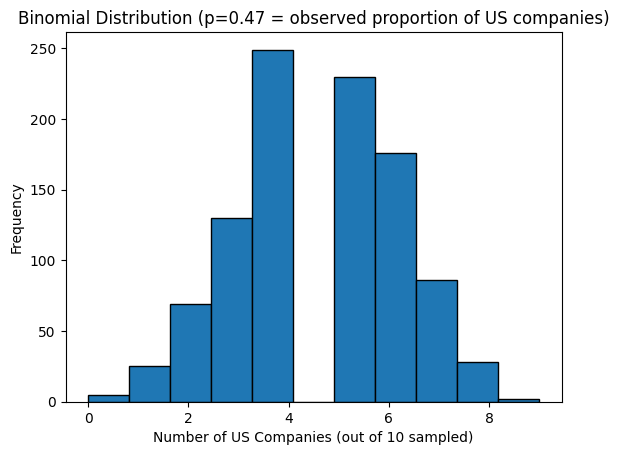

In [31]:
plt.hist(binomial_data, bins=11, edgecolor="black")
plt.xlabel("Number of US Companies (out of 10 sampled)")
plt.ylabel("Frequency")
plt.title(f"Binomial Distribution (p={p_us:.2f} = observed proportion of US companies)")
plt.show()

In [32]:
# Poisson: number of companies per country is a genuine count variable.
# The US is excluded because it dominates the list and would break the Poisson assumption.
counts = df.loc[df["Country"] != "United States", "Country"].value_counts()
lam = counts.mean()

print("Companies per country (non-US):\n", counts.to_string(), "\n")
print("Mean:", round(lam, 2), "| Variance:", round(counts.var(), 2), "| Dispersion (var/mean):", round(counts.var() / lam, 2))
print("Poisson needs variance = mean (dispersion near 1). Far from 1 means Poisson is only a rough approximation.")

Companies per country (non-US):
 Country
United Kingdom    9
Canada            9
China             7
Brazil            6
Japan             5
India             5
Taiwan            3
Israel            3
Netherlands       3
Ireland           2
Germany           2
Switzerland       2
France            2
South Korea       1
Denmark           1
Belgium           1
Finland           1
Uruguay           1
Australia         1 

Mean: 3.37 | Variance: 7.25 | Dispersion (var/mean): 2.15
Poisson needs variance = mean (dispersion near 1). Far from 1 means Poisson is only a rough approximation.


In [33]:
poisson_data = np.random.poisson(lam, 1000)

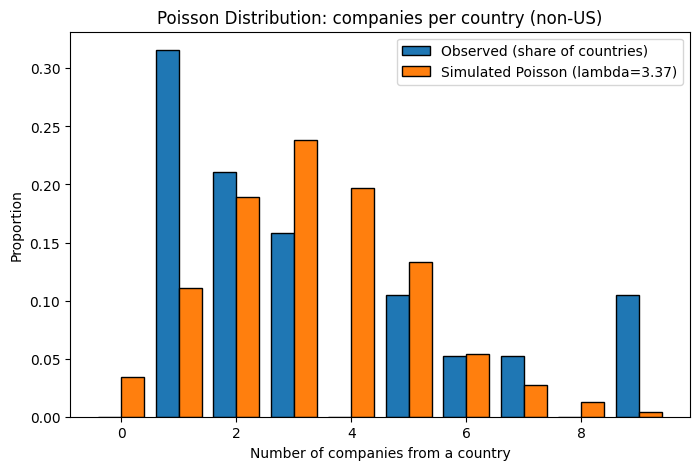

In [34]:
k_max = int(max(counts.max(), poisson_data.max()))
obs = np.bincount(counts.values, minlength=k_max + 1) / len(counts)
sim = np.bincount(poisson_data, minlength=k_max + 1) / len(poisson_data)
ks = np.arange(k_max + 1)

plt.figure(figsize=(8, 5))
plt.bar(ks - 0.2, obs, width=0.4, edgecolor="black", label="Observed (share of countries)")
plt.bar(ks + 0.2, sim, width=0.4, edgecolor="black", label=f"Simulated Poisson (lambda={lam:.2f})")
plt.xlabel("Number of companies from a country")
plt.ylabel("Proportion")
plt.title("Poisson Distribution: companies per country (non-US)")
plt.legend()
plt.show()

## Sampling Techniques

Simple random sampling, sampling with replacement, systematic sampling, stratified sampling, and cluster sampling — applied to the Market Cap dataset.

In [35]:
sample1 = df.sample(n=15, random_state=1)
sample1

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B,Region,PS_Ratio,log_MarketCap,log_Revenue,log_Employees,Cap_Tier,Sector_Group
95,SU,Suncor Energy Inc.,Canada,Energy,91661246464,56570998784,15424.0,USD,CAD,91.661246,40.483038,Non-US,2.264189,1.962186,1.607273,4.188197,Low,Energy
54,SBUX,Starbucks Corporation,United States,Consumer Cyclical,120281399296,38338301952,381000.0,USD,USD,120.281399,38.338302,US,3.137369,2.080198,1.583633,5.580925,Medium,Consumer Cyclical
59,UMC,United Microelectronics Corporation,Taiwan,Technology,45240602624,265819226112,20000.0,USD,TWD,45.240603,8.148465,Non-US,5.552040,1.655528,0.911076,4.301030,Low,Technology
117,TEVA,Teva Pharmaceutical Industries Limited,Israel,Healthcare,48366157824,17315000320,31173.0,USD,USD,48.366158,17.315000,Non-US,2.793310,1.684542,1.238423,4.493779,Low,Healthcare
77,DEO,Diageo plc,United Kingdom,Consumer Defensive,50792730624,19643000832,27972.0,USD,USD,50.792731,19.643001,Non-US,2.585793,1.705802,1.293208,4.446724,Low,Consumer Defensive
46,CAT,Caterpillar Inc.,United States,Industrials,297588916224,74728996864,118000.0,USD,USD,297.588916,74.728997,US,3.982242,2.473617,1.873489,5.071882,High,Industrials
31,LLY,Eli Lilly and Company,United States,Healthcare,1224985149440,79666003968,50000.0,USD,USD,1224.985149,79.666004,US,15.376511,3.088131,1.901273,4.698970,High,Healthcare
81,BTI,British American Tobacco p.l.c.,United Kingdom,Consumer Defensive,131248996352,25776001024,47797.0,USD,GBP,131.248996,34.502792,Non-US,3.804011,2.118096,1.537854,4.679401,Medium,Consumer Defensive
48,HON,Honeywell International Inc.,United States,Industrials,70405054464,37743001600,101000.0,USD,USD,70.405054,37.743002,US,1.865380,1.847604,1.576836,5.004321,Low,Industrials
98,PDD,PDD Holdings Inc.,Ireland,Consumer Cyclical,112846872576,450775711744,25474.0,USD,CNY,112.846873,67.698273,Non-US,1.666909,2.052490,1.830578,4.406097,Low,Consumer Cyclical


In [36]:
sample2 = df.sample(n=15, replace=True, random_state=1)
sample2

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B,Region,PS_Ratio,log_MarketCap,log_Revenue,log_Employees,Cap_Tier,Sector_Group
37,AMD,"Advanced Micro Devices, Inc.",United States,Technology,924666494976,41305001984,31000.0,USD,USD,924.666495,41.305002,US,22.386308,2.965985,1.616003,4.491362,High,Technology
107,WIT,Wipro Limited,India,Technology,20875814912,970234003456,240000.0,USD,INR,20.875815,10.185916,Non-US,2.049478,1.319643,1.008000,5.380211,Low,Technology
12,XOM,ExxonMobil Holdings Corporation,United States,Energy,753672323072,361060007936,57900.0,USD,USD,753.672323,361.060008,US,2.087388,2.877183,2.557579,4.762679,High,Energy
72,NVS,Novartis AG,Switzerland,Healthcare,304257269760,57364000768,75267.0,USD,USD,304.257270,57.364001,Non-US,5.303976,2.483241,1.758639,4.876605,High,Healthcare
9,JNJ,Johnson & Johnson,United States,Healthcare,662491824128,99334995968,138200.0,USD,USD,662.491824,99.334996,US,6.669269,2.821181,1.997102,5.140508,High,Healthcare
75,BP,BP p.l.c.,United Kingdom,Energy,129681022976,215465000960,93700.0,USD,USD,129.681023,215.465001,Non-US,0.601866,2.112876,2.333377,4.971740,Medium,Energy
5,META,"Meta Platforms, Inc.",United States,Communication Services,1596793421824,241605001216,66775.0,USD,USD,1596.793422,241.605001,US,6.609107,3.203249,2.383106,4.824614,High,Communication Services
79,TTE,TotalEnergies SE,France,Energy,207086256128,196381999104,94847.0,USD,USD,207.086256,196.381999,Non-US,1.054507,2.316151,2.293102,4.977024,Medium,Energy
64,MUFG,"Mitsubishi UFJ Financial Group, Inc.",Japan,Financial Services,246951493632,7260459237376,156000.0,USD,JPY,246.951494,46.102544,Non-US,5.356570,2.392612,1.663725,5.193125,Medium,Financial Services
16,KO,The Coca-Cola Company,United States,Consumer Defensive,399302557696,51053998080,65900.0,USD,USD,399.302558,51.053998,US,7.821181,2.601302,1.708030,4.818885,High,Consumer Defensive


In [37]:
k = 3
systematic_sample = df.iloc[::k]
systematic_sample

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B,Region,PS_Ratio,log_MarketCap,log_Revenue,log_Employees,Cap_Tier,Sector_Group
0,AAPL,Apple Inc.,United States,Technology,5092055449600,466822987776,150000.0,USD,USD,5092.055450,466.822988,US,10.907894,3.706893,2.669152,5.176091,High,Technology
3,AMZN,"Amazon.com, Inc.",United States,Consumer Cyclical,2629595299840,775680032768,1595000.0,USD,USD,2629.595300,775.680033,US,3.390052,3.419889,2.889683,6.202761,High,Consumer Cyclical
6,TSLA,"Tesla, Inc.",United States,Consumer Cyclical,1594136068096,103569997824,134785.0,USD,USD,1594.136068,103.569998,US,15.391871,3.202525,2.015234,5.129642,High,Consumer Cyclical
9,JNJ,Johnson & Johnson,United States,Healthcare,662491824128,99334995968,138200.0,USD,USD,662.491824,99.334996,US,6.669269,2.821181,1.997102,5.140508,High,Healthcare
12,XOM,ExxonMobil Holdings Corporation,United States,Energy,753672323072,361060007936,57900.0,USD,USD,753.672323,361.060008,US,2.087388,2.877183,2.557579,4.762679,High,Energy
15,CVX,Chevron Corporation,United States,Energy,454032719872,209383997440,43039.0,USD,USD,454.032720,209.383997,US,2.168421,2.657087,2.320943,4.633862,High,Energy
18,COST,Costco Wholesale Corporation,United States,Consumer Defensive,441392300032,303154003968,355000.0,USD,USD,441.392300,303.154004,US,1.456000,2.644825,2.481663,5.550228,High,Consumer Defensive
21,DIS,The Walt Disney Company,United States,Communication Services,191506841600,98860998656,175560.0,USD,USD,191.506842,98.860999,US,1.937132,2.282184,1.995025,5.244426,Medium,Communication Services
24,NFLX,"Netflix, Inc.",United States,Communication Services,258372452352,49734631424,16000.0,USD,USD,258.372452,49.734631,US,5.195021,2.412246,1.696659,4.204120,Medium,Communication Services
27,PFE,Pfizer Inc.,United States,Healthcare,170705223680,63695998976,75000.0,USD,USD,170.705224,63.695999,US,2.679999,2.232247,1.804112,4.875061,Medium,Healthcare


In [38]:
# Stratify by Market Cap tier so every stratum has enough members

In [39]:
print(df["Cap_Tier"].value_counts())   # tiers were created earlier, in the "New columns" cell

Cap_Tier
Low       40
Medium    40
High      40
Name: count, dtype: int64


In [40]:
# groupby().sample() draws within each tier directly (no deprecated .apply, grouping column kept)
stratified_sample = df.groupby("Cap_Tier", observed=True).sample(n=4, random_state=1)

In [41]:
stratified_sample

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B,Region,PS_Ratio,log_MarketCap,log_Revenue,log_Employees,Cap_Tier,Sector_Group
48,HON,Honeywell International Inc.,United States,Industrials,70405054464,37743001600,101000.0,USD,USD,70.405054,37.743002,US,1.865380,1.847604,1.576836,5.004321,Low,Industrials
109,VALE,Vale S.A.,Brazil,Basic Materials,47579426816,218068992000,65805.0,USD,BRL,47.579427,40.686033,Non-US,1.169429,1.677419,1.609445,4.818259,Low,Other
49,UPS,"United Parcel Service, Inc.",United States,Industrials,91314388992,91367997440,460000.0,USD,USD,91.314389,91.367997,US,0.999413,1.960539,1.960794,5.662758,Low,Industrials
99,JD,"JD.com, Inc.",China,Consumer Cyclical,34613313536,1313438040064,900000.0,USD,CNY,34.613314,197.254388,Non-US,0.175476,1.539243,2.295027,5.954243,Low,Consumer Cyclical
79,TTE,TotalEnergies SE,France,Energy,207086256128,196381999104,94847.0,USD,USD,207.086256,196.381999,Non-US,1.054507,2.316151,2.293102,4.977024,Medium,Energy
62,TM,Toyota Motor Corporation,Japan,Consumer Cyclical,231592116224,51957024686080,367990.0,USD,JPY,231.592116,329.917290,Non-US,0.701970,2.364724,2.518405,5.565836,Medium,Consumer Cyclical
69,NVO,Novo Nordisk A/S,Denmark,Healthcare,172634210304,329430990848,66700.0,USD,DKK,172.634210,49.309668,Non-US,3.501022,2.237127,1.692932,4.824126,Medium,Healthcare
28,ABT,Abbott Laboratories,United States,Healthcare,180946190336,48228999168,122000.0,USD,USD,180.946190,48.228999,US,3.751813,2.257549,1.683308,5.086360,Medium,Healthcare
33,ABBV,AbbVie Inc.,United States,Healthcare,513860042752,64385998848,57000.0,USD,USD,513.860043,64.385999,US,7.980928,2.710845,1.808791,4.755875,High,Healthcare
29,ORCL,Oracle Corporation,United States,Technology,423076265984,71776002048,141000.0,USD,USD,423.076266,71.776002,US,5.894397,2.626419,1.855979,5.149219,High,Technology


In [42]:
# Cluster sampling: randomly pick whole countries, keep every company in them. Seeded so results reproduce.
rng = np.random.default_rng(1)
clusters = rng.choice(df["Country"].unique(), 2, replace=False)
print("Selected Clusters:", clusters)

Selected Clusters: ['Denmark' 'France']


In [43]:
cluster_sample = df[df["Country"].isin(clusters)]
cluster_sample.style.background_gradient(cmap='Greens', subset=['MarketCap_B'])

,Ticker,Company,Country,Sector,MarketCap,Revenue,Employees,CapCurrency,RevCurrency,MarketCap_B,Revenue_B,Region,PS_Ratio,log_MarketCap,log_Revenue,log_Employees,Cap_Tier,Sector_Group
69,NVO,Novo Nordisk A/S,Denmark,Healthcare,172634210304,329430990848,66700.000000,USD,DKK,172.634210,49.309668,Non-US,3.501022,2.237127,1.692932,4.824126,Medium,Healthcare
78,SNY,Sanofi,France,Healthcare,103345414144,48918999040,74846.000000,USD,EUR,103.345414,54.731481,Non-US,1.888226,2.014291,1.738237,4.874169,Low,Healthcare
79,TTE,TotalEnergies SE,France,Energy,207086256128,196381999104,94847.000000,USD,USD,207.086256,196.381999,Non-US,1.054507,2.316151,2.293102,4.977024,Medium,Energy


In [44]:
population_mean = df["MarketCap_B"].mean()
population_median = df["MarketCap_B"].median()
population_std = df["MarketCap_B"].std()

sample_mean = sample1["MarketCap_B"].mean()
sample_median = sample1["MarketCap_B"].median()
sample_std = sample1["MarketCap_B"].std()

replacement_mean = sample2["MarketCap_B"].mean()
replacement_median = sample2["MarketCap_B"].median()
replacement_std = sample2["MarketCap_B"].std()

comparison = pd.DataFrame({
    "Statistic": ["Size", "Mean", "Median", "Standard Deviation"],
    "Population": [len(df), population_mean, population_median, population_std],
    "Sample": [len(sample1), sample_mean, sample_median, sample_std],
    "Sample With Replacement": [len(sample2), replacement_mean, replacement_median, replacement_std],
})
comparison

,Statistic,Population,Sample,Sample With Replacement
0,Size,120.000000,15.000000,15.000000
1,Mean,444.515125,422.902066,759.381460
2,Median,186.175906,112.846873,304.257270
3,Standard Deviation,860.663050,895.815801,1011.927884


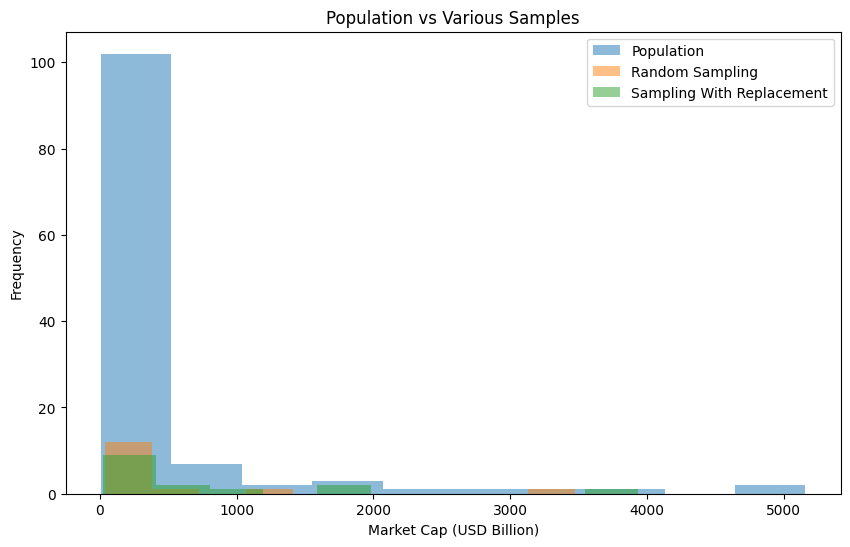

In [45]:
plt.figure(figsize=(10, 6))
plt.hist(df["MarketCap_B"], bins=10, alpha=0.5, label="Population")
plt.hist(sample1["MarketCap_B"], bins=10, alpha=0.5, label="Random Sampling")
plt.hist(sample2["MarketCap_B"], bins=10, alpha=0.5, label="Sampling With Replacement")
plt.xlabel("Market Cap (USD Billion)")
plt.ylabel("Frequency")
plt.title("Population vs Various Samples")
plt.legend()
plt.show()

## Central Limit Theorem

In [46]:
means = []

In [47]:
for i in range(1000):
    sample = df["MarketCap_B"].sample(n=10, replace=True, random_state=i)
    means.append(sample.mean())

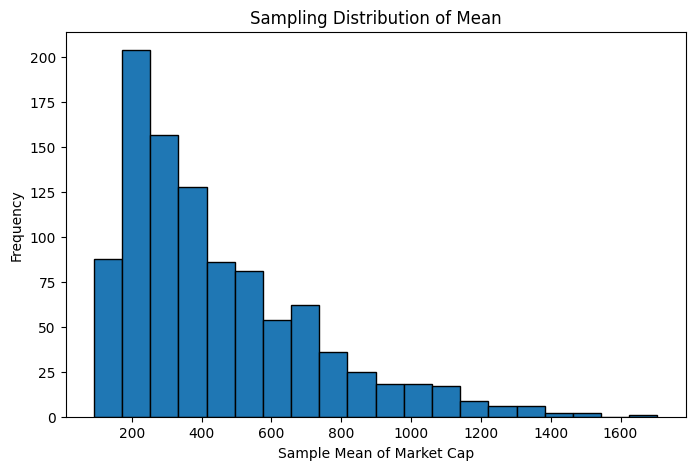

In [48]:
plt.figure(figsize=(8, 5))
plt.hist(means, bins=20, edgecolor="black")
plt.xlabel("Sample Mean of Market Cap")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of Mean")
plt.show()

In [49]:
print("Population Mean:", population_mean)
print("Mean of Sample Means:", np.mean(means))
print("Theoretical standard error (pop. SD / sqrt(n)):", df["MarketCap_B"].std(ddof=0) / np.sqrt(10))
print("Observed SD of the sample means               :", np.std(means, ddof=1))
print("Skewness of sample means (0 = symmetric)      :", pd.Series(means).skew())

Population Mean: 444.51512487680003
Mean of Sample Means: 445.82530991569917
Theoretical standard error (pop. SD / sqrt(n)): 271.0291580003585
Observed SD of the sample means               : 275.24161481371317
Skewness of sample means (0 = symmetric)      : 1.2822738505943982


With n = 10 and such a skewed population, the sampling distribution is still visibly right-skewed. The next cell repeats the experiment with bigger samples.

n = 10 | SD of sample means: 275.1 | skewness: 1.28
n = 30 | SD of sample means: 154.0 | skewness: 0.69
n = 100 | SD of sample means: 84.5 | skewness: 0.38


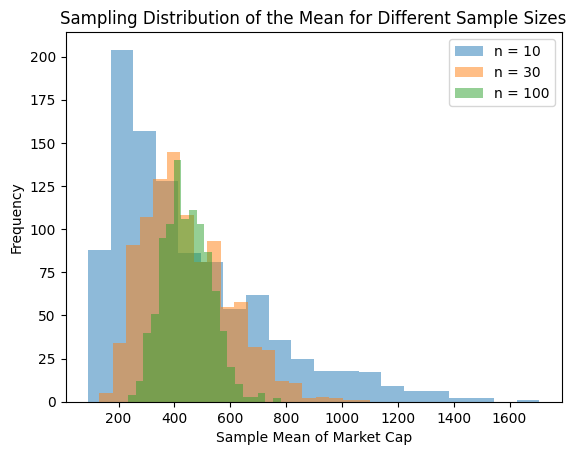

In [50]:
# Effect of the sample size on the sampling distribution of the mean
for n in [10, 30, 100]:
    means_n = []
    for i in range(1000):
        means_n.append(df["MarketCap_B"].sample(n=n, replace=True, random_state=i).mean())
    plt.hist(means_n, bins=20, alpha=0.5, label=f"n = {n}")
    print("n =", n, "| SD of sample means:", round(np.std(means_n), 1), "| skewness:", round(pd.Series(means_n).skew(), 2))

plt.xlabel("Sample Mean of Market Cap")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of the Mean for Different Sample Sizes")
plt.legend()
plt.show()

As n grows, the sample means become less spread out and more symmetric (skewness moves towards 0), even though the population is very skewed. That is the Central Limit Theorem.

## Simple Linear Regression: Predicting Market Cap from Revenue

Revenue and market cap both span several orders of magnitude, so a straight line on the raw values is dominated by a few giants. We fit the line on the raw values (Model A) and on the log10 values (Model B), and compare them.

In [51]:
# Model A: raw values
X = df[["Revenue_B"]]
y = df["MarketCap_B"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

model_raw = LinearRegression()
model_raw.fit(X_train, y_train)
y_pred = model_raw.predict(X_test)

print("Intercept:", model_raw.intercept_)
print("Coefficient:", model_raw.coef_[0])
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Training Data: 96
Testing Data: 24
Intercept: 37.3764571400809
Coefficient: 3.8612531791035782
Mean Absolute Error: 591.5048579892948
Mean Squared Error: 1390401.0937500105
R2 Score: 0.2491560823911173


In [52]:
# Model B: log10 values
X = df[["log_Revenue"]]
y = df["log_MarketCap"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_log = LinearRegression()
model_log.fit(X_train, y_train)
y_pred = model_log.predict(X_test)

print("Intercept:", model_log.intercept_)
print("Coefficient:", model_log.coef_[0])
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Intercept: 0.7286753435720481
Coefficient: 0.8779079297862812
Mean Absolute Error: 0.32895723811231065
Mean Squared Error: 0.15225940744862573
R2 Score: 0.5004151196365463


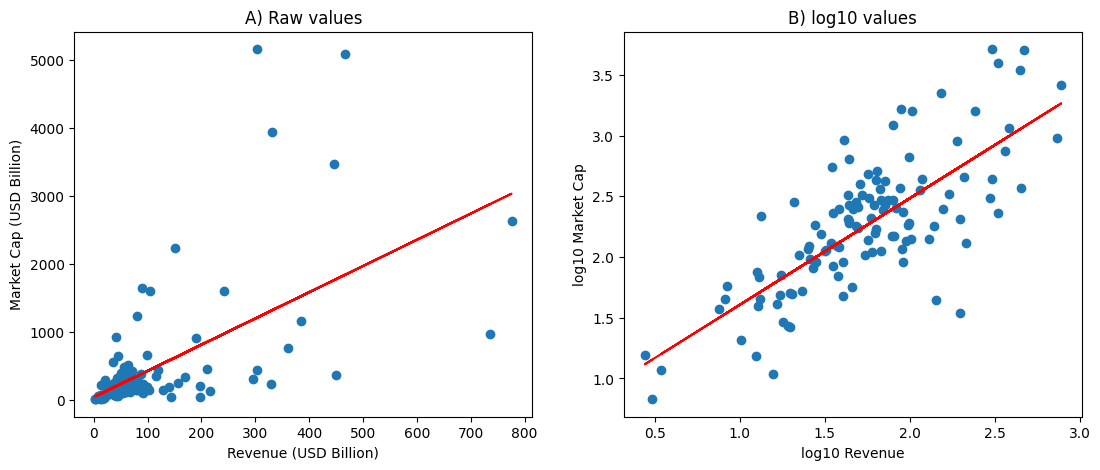

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["Revenue_B"], df["MarketCap_B"])
axes[0].plot(df["Revenue_B"], model_raw.predict(df[["Revenue_B"]]), color="red")
axes[0].set_xlabel("Revenue (USD Billion)")
axes[0].set_ylabel("Market Cap (USD Billion)")
axes[0].set_title("A) Raw values")

axes[1].scatter(df["log_Revenue"], df["log_MarketCap"])
axes[1].plot(df["log_Revenue"], model_log.predict(df[["log_Revenue"]]), color="red")
axes[1].set_xlabel("log10 Revenue")
axes[1].set_ylabel("log10 Market Cap")
axes[1].set_title("B) log10 values")

plt.show()

In [54]:
# Statistical summary of Model B on the full data: p-value and confidence interval of the slope
ols_model = sm.OLS(df["log_MarketCap"], sm.add_constant(df["log_Revenue"])).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:          log_MarketCap   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.564
Method:                 Least Squares   F-statistic:                     155.0
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           3.13e-23
Time:                        05:10:42   Log-Likelihood:                -48.278
No. Observations:                 120   AIC:                             100.6
Df Residuals:                     118   BIC:                             106.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.7454      0.127      5.888      

**How to read this:**
- In the log model the slope is an *elasticity*: a 1% rise in revenue goes with roughly (slope)% rise in market cap.
- R² is how much of the variation in market cap revenue explains. The rest is what revenue does not capture: growth, profit margins, sector.
- This shows association, not that revenue *causes* market cap. With a small sample, treat the numbers as indicative.

---
# Part B: Lab Practicals Applied to the Market Cap Dataset

Each section repeats the method from one lab practical on the market-cap data (`df`). The order follows the practical numbers: **5, 5-II, 6, 6 B&C, 7, 8-B, 8-C**.

- Market cap and revenue are heavily right-skewed, so the t-tests, ANOVA and regression use the **log10 scale**.
- The test set in every train/test split is small, so scores are noisy. Treat results as indicative.

---
# Practical No. 05: Descriptive Statistics, Confidence Interval and One-Sample t-test

Variable: `MarketCap_B` (USD billion).

In [55]:
data = df["MarketCap_B"].dropna()

mean_val = data.mean()
print("Mean:", mean_val)
median_val = data.median()
print("Median:", median_val)
# Market cap is continuous (every value is different), so its mode is meaningless.
# The mode of a category is useful instead:
print("Mode of Sector:", df["Sector"].mode().tolist())
data_range = data.max() - data.min()
print("Range:", data_range)
print("Variance:", data.var())
print("Standard Deviation:", data.std())
print("Skewness:", data.skew())

# IQR: spread of the middle 50% of the data
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

if mean_val > median_val:
    print("Mean > Median: the data is right-skewed (a few giant companies pull the mean up).")

Mean: 444.51512487680003
Median: 186.17590579199998
Mode of Sector: ['Technology']
Range: 5152.510109184
Variance: 740740.8855769746
Standard Deviation: 860.6630499661145
Skewness: 3.9500225730659513
Q1: 91.524323328
Q3: 334.671618048
IQR: 243.14729472000005
Mean > Median: the data is right-skewed (a few giant companies pull the mean up).


In [56]:
# Confidence Interval: estimates the population mean
confidence = 0.95
sem = stats.sem(data)
confidence_interval = stats.t.interval(confidence, len(data) - 1, loc=data.mean(), scale=sem)
print("Confidence Interval: ", confidence_interval)

Confidence Interval:  (np.float64(288.94377077328954), np.float64(600.0864789803105))


**Hypothesis test (one-sample t-test, two-tailed)**
- H0: the mean market cap = 500 (USD billion). 500 is a round benchmark for "very large company".
- H1: the mean market cap is not 500.

The raw-value test assumes roughly normal data, which is not true here (see the skewness). So we also test on the log scale, where H0 says the *geometric mean* market cap is 500.

In [57]:
benchmark = 500   # USD billion

t_stat, p_value = stats.ttest_1samp(data, popmean=benchmark)
print("Raw values: t-statistic =", t_stat, "| p-value =", p_value)
if p_value < alpha:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

t_stat, p_value = stats.ttest_1samp(df["log_MarketCap"], popmean=np.log10(benchmark))
print("\nLog10 values: t-statistic =", t_stat, "| p-value =", p_value)
if p_value < alpha:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

Raw values: t-statistic = -0.7062070971103127 | p-value = 0.4814397125532883
Fail to Reject the Null Hypothesis

Log10 values: t-statistic = -8.585119485929543 | p-value = 4.077047190458926e-14
Reject the Null Hypothesis


---
# Practical No. 05-II: Two-Sample t-test, Paired t-test, ANOVA and Two-Way ANOVA

All tests use `log_MarketCap` unless stated.

### Two-sample t-test: US vs Non-US companies
H0: mean(US) = mean(Non-US), so H1 is that they are not equal.

We use `equal_var=False` (Welch's t-test) because the two groups have different sizes.

In [58]:
group_US = df[df["Region"] == "US"]["log_MarketCap"]
group_NonUS = df[df["Region"] == "Non-US"]["log_MarketCap"]
print("US companies:", len(group_US), "| Non-US companies:", len(group_NonUS))

diff_mean = group_US.mean() - group_NonUS.mean()
print("Difference in means (log10):", diff_mean)
print("Typical US company is", round(10 ** diff_mean, 2), "times the size of a Non-US company")

se = np.sqrt(group_US.var() / len(group_US) + group_NonUS.var() / len(group_NonUS))
dfree = len(group_US) + len(group_NonUS) - 2
print("Degrees of freedom:", dfree)
print(stats.t.interval(0.95, dfree, loc=diff_mean, scale=se))

t_stat, p_value = stats.ttest_ind(group_US, group_NonUS, equal_var=False)
print("t-statistic:", t_stat)
print("p-value:", p_value)
p_two_sample = p_value
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

US companies: 56 | Non-US companies: 64
Difference in means (log10): 0.6258725299000436
Typical US company is 4.23 times the size of a Non-US company
Degrees of freedom: 118
(np.float64(0.4602062173407378), np.float64(0.7915388424593495))
t-statistic: 7.48129166018255
p-value: 1.5590251324129657e-11
Reject the null hypothesis


### Paired t-test: market cap vs revenue of the same company
H0: mean(log market cap) = mean(log revenue)

Each company gives one pair. The difference of the logs is log(market cap / revenue), so this tests whether the typical price-to-sales ratio differs from 1. Most large companies are valued above one year of sales, so a rejection is expected. It is a demonstration of the method more than a discovery.

In [59]:
print("Mean of log10 Market Cap:", df["log_MarketCap"].mean())
print("Mean of log10 Revenue:", df["log_Revenue"].mean(), "\n")

t_stat, p_value = stats.ttest_rel(df["log_MarketCap"], df["log_Revenue"])
print("t-statistic:", t_stat)
print("p-value:", p_value, "\n")

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Mean of log10 Market Cap: 2.2658865165678934
Mean of log10 Revenue: 1.739519501096333 

t-statistic: 15.658045655909632
p-value: 1.1081042638910113e-30 

Reject the null hypothesis


### ANOVA: market cap across sectors
H0: the mean market cap of all sectors is the same. Only sectors with at least 5 companies are used.

In [60]:
anova_df = df[df["Sector_Group"] != "Other"]
print(anova_df.groupby("Sector_Group")["log_MarketCap"].agg(["count", "mean"]), "\n")

groups = [g.values for name, g in anova_df.groupby("Sector_Group")["log_MarketCap"]]
f_stat, p_value = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("p-value:", p_value, "\n")
p_anova = p_value

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

                        count      mean
Sector_Group                           
Communication Services     10  2.334593
Consumer Cyclical          15  2.095912
Consumer Defensive         11  2.304344
Energy                      9  2.295157
Financial Services         21  2.256315
Healthcare                 17  2.264025
Industrials                 9  2.130976
Technology                 25  2.388280 

F-statistic: 0.46497789478906826
p-value: 0.8579407523210186 

Fail to reject the null hypothesis


### Two-Way ANOVA: Region and Sector
Factors: Region (US / Non-US) and the 3 largest sectors, plus their interaction. The cells are small and unbalanced, so the interaction is weak evidence at best.

In [61]:
top3 = df["Sector"].value_counts().head(3).index
sub = df[df["Sector"].isin(top3)]
print("Companies in each cell:")
print(pd.crosstab(sub["Region"], sub["Sector"]), "\n")

model_2way = ols("log_MarketCap ~ C(Region) + C(Sector) + C(Region):C(Sector)", data=sub).fit()

# Anova Table
anova_table = sm.stats.anova_lm(model_2way, typ=2)
print(anova_table)

Companies in each cell:
Sector  Financial Services  Healthcare  Technology
Region                                            
Non-US                  14           8          12
US                       7           9          13 

                        sum_sq    df          F        PR(>F)
C(Region)             8.003161   1.0  33.373853  3.325321e-07
C(Sector)             0.217372   2.0   0.453230  6.378425e-01
C(Region):C(Sector)   0.253868   2.0   0.529325  5.918694e-01
Residual             13.668789  57.0        NaN           NaN


**Assignment:** the same two-way ANOVA on `log_Revenue`.

In [62]:
model_revenue = ols("log_Revenue ~ C(Region) + C(Sector) + C(Region):C(Sector)", data=sub).fit()

# Generate the ANOVA table
anova_table_revenue = sm.stats.anova_lm(model_revenue, typ=2)
print("Two-Way ANOVA Table for log10 Revenue:")
print(anova_table_revenue)

Two-Way ANOVA Table for log10 Revenue:
                       sum_sq    df          F        PR(>F)
C(Region)            4.691881   1.0  30.892595  7.520659e-07
C(Sector)            0.253172   2.0   0.833476  4.397621e-01
C(Region):C(Sector)  0.102286   2.0   0.336741  7.155049e-01
Residual             8.657001  57.0        NaN           NaN


---
# Practical No. 06: Chi-Square Test

Test of independence between **Region** (US / Non-US) and **Market Cap Tier** (Low / Medium / High).
- H0: Region and market-cap tier are independent
- H1: there is a relationship between Region and market-cap tier

In [63]:
# Create Contingency table
observed = pd.crosstab(df["Region"], df["Cap_Tier"])
print("Contingency Table")
print(observed)

# Perform Chi-Square Test
chi2, p, dof, expected = chi2_contingency(observed)

# Expected Value
expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
print("\nExpected Values")
print(expected)
print("\nChi-Square Statistics:", chi2)
print("Degree of Freedom:", dof)
print("P-Value:", p)
p_chi = p

# The test is reliable only if the expected counts are not too small (rule of thumb: at least 5)
if expected.values.min() < 5:
    print("\nWARNING: some expected counts are below 5, so be careful with this p-value.")

# Interpretation
if p < alpha:
    print("\nReject H0: There is a relationship between Region and market-cap tier")
else:
    print("\nFail to reject H0: There is no evidence of a relationship between Region and market-cap tier")

Contingency Table
Cap_Tier  Low  Medium  High
Region                     
Non-US     36      21     7
US          4      19    33

Expected Values
Cap_Tier        Low     Medium       High
Region                                   
Non-US    21.333333  21.333333  21.333333
US        18.666667  18.666667  18.666667

Chi-Square Statistics: 42.254464285714285
Degree of Freedom: 2
P-Value: 6.676666173085393e-10

Reject H0: There is a relationship between Region and market-cap tier


---
# Practical No. 06 (Part B and C): Covariance, Correlation and Hypothesis Testing for Correlation

**AIM:** compute covariance, Pearson and Spearman correlation between Revenue and Market Cap, test their significance and interpret the strength.

### Part B: Covariance and correlation
Covariance gives the *direction* only, and its size depends on the units. Correlation is covariance divided by both standard deviations, so it always lies between -1 and +1.

In [64]:
# Calculating Covariance and Pearson Correlation
Covariance = df["Revenue_B"].cov(df["MarketCap_B"])
Correlation = df["Revenue_B"].corr(df["MarketCap_B"])
Correlation_log = df["log_Revenue"].corr(df["log_MarketCap"])

print("Covariance (raw values):", Covariance)
print("Correlation (raw values):", Correlation)
print("Correlation (log10 values):", Correlation_log)

# Interpretation
for r in [Correlation, Correlation_log]:
    if r > 0:
        print("\nDirection: Positive")
    elif r < 0:
        print("\nDirection: Negative")
    else:
        print("\nNo Linear Relationship between the variables.")

    if abs(r) > 0.7:
        print("Strength: Strong")
    elif abs(r) > 0.4:
        print("Strength: Moderate")
    elif abs(r) > 0:
        print("Strength: Weak")

Covariance (raw values): 68031.29940983976
Correlation (raw values): 0.6027783831241786
Correlation (log10 values): 0.7534665689611888

Direction: Positive
Strength: Moderate

Direction: Positive
Strength: Strong


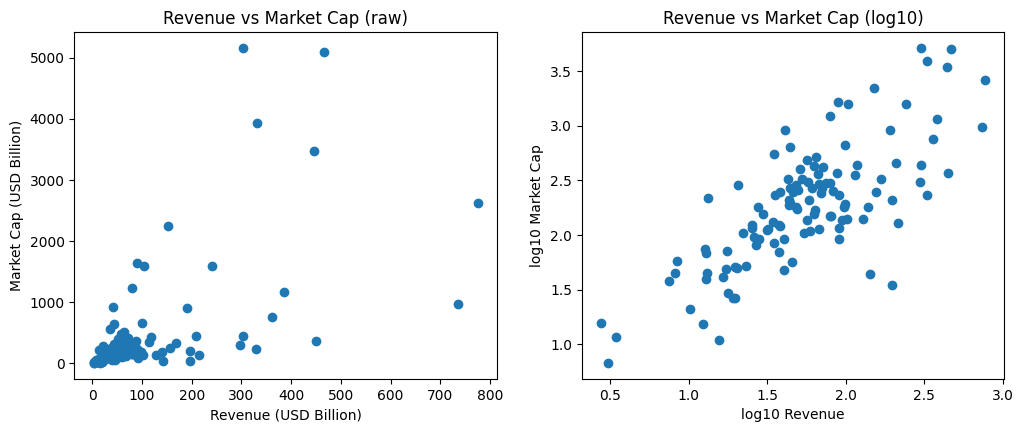

In [65]:
# Scatter Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(df["Revenue_B"], df["MarketCap_B"])
axes[0].set_xlabel("Revenue (USD Billion)")
axes[0].set_ylabel("Market Cap (USD Billion)")
axes[0].set_title("Revenue vs Market Cap (raw)")
axes[1].scatter(df["log_Revenue"], df["log_MarketCap"])
axes[1].set_xlabel("log10 Revenue")
axes[1].set_ylabel("log10 Market Cap")
axes[1].set_title("Revenue vs Market Cap (log10)")
plt.show()

### Part C: Hypothesis test for correlation
- H0: there is no correlation in the population
- H1: there is a correlation

**Pearson** needs continuous data with a roughly linear relationship, and extreme outliers distort it. **Spearman** works on ranks, needs only a monotonic relationship, and is not distorted by a few giants.

In [66]:
X = df["Revenue_B"]
Y = df["MarketCap_B"]

# Pearson Coefficient (raw values)
Pearson_r, Pearson_p = pearsonr(X, Y)
print("Pearson (raw) Correlation Coefficient:", Pearson_r)
print("p-value:", Pearson_p)
if Pearson_p < alpha:
    print("Decision: Reject H0")
    print("Conclusion: The Correlation is Statistically significant.")
else:
    print("Decision: Failed to Reject H0")
    print("Conclusion: The correlation is not statistically significant")

# Pearson Coefficient (log10 values)
Pearson_r_log, Pearson_p_log = pearsonr(df["log_Revenue"], df["log_MarketCap"])
print("\nPearson (log10) Correlation Coefficient:", Pearson_r_log)
print("p-value:", Pearson_p_log)
if Pearson_p_log < alpha:
    print("Decision: Reject H0")
    print("Conclusion: The Correlation is Statistically significant.")
else:
    print("Decision: Failed to Reject H0")
    print("Conclusion: The correlation is not statistically significant")

# Spearman Coefficient (ranks)
spearman_r, spearman_p = spearmanr(X, Y)
print("\nSpearman Correlation Coefficient:", spearman_r)
print("p-value:", spearman_p)
if spearman_p < alpha:
    print("Decision: Reject H0")
    print("Conclusion: The Correlation is Statistically significant.")
else:
    print("Decision: Failed to Reject H0")
    print("Conclusion: The correlation is not statistically significant")

Pearson (raw) Correlation Coefficient: 0.6027783831241795
p-value: 3.230479927778628e-13
Decision: Reject H0
Conclusion: The Correlation is Statistically significant.

Pearson (log10) Correlation Coefficient: 0.7534665689611887
p-value: 3.13275239881165e-23
Decision: Reject H0
Conclusion: The Correlation is Statistically significant.

Spearman Correlation Coefficient: 0.6990138204041947
p-value: 6.803741171722229e-19
Decision: Reject H0
Conclusion: The Correlation is Statistically significant.


**Why do the p-values differ?** They test different things. Raw Pearson is dominated by a few giant companies. Log Pearson measures a straight-line relationship between the logs. Spearman only looks at the rank order. If raw Pearson is weak but the other two are strong, the relationship is real but not a straight line in raw dollars.

---
# Practical No. 07: Regression (Linear, Ridge, Lasso, Decision Tree, Random Forest)

Predict **log10 Market Cap** from **log10 Revenue** and **log10 Employees**.

- Lasso uses `alpha=0.05`, not 1.0: the target is on a small scale, and alpha 1.0 would shrink every coefficient to zero.
- A **baseline** model (always predicts the average) is added. A model that cannot beat it has learned nothing.

In [67]:
# Feature Selection
X = df[["log_Revenue", "log_Employees"]]
X = X.fillna(X.median())          # one or two companies have no employee count
y = df["log_MarketCap"]
print("Independent Variables (X):", list(X.columns))
print("Dependent Variable (y): log10 Market Cap (USD billion)")

# Splitting into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Sample:", len(X_train))
print("Testing Sample:", len(X_test))

# Standardisation (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Simple Linear Model
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
print("Intercept:", round(linear_model.intercept_, 3))
coef = pd.Series(linear_model.coef_, index=X.columns).round(3)
print("Coefficients (on standardised features):")
print(coef)

Independent Variables (X): ['log_Revenue', 'log_Employees']
Dependent Variable (y): log10 Market Cap (USD billion)
Training Sample: 96
Testing Sample: 24
Intercept: 2.227
Coefficients (on standardised features):
log_Revenue      0.466
log_Employees   -0.088
dtype: float64


In [68]:
# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
print("Ridge Regression")
print("=" * 50)
print("Alpha:", ridge_model.alpha)
print(pd.Series(ridge_model.coef_, index=X.columns).round(3))

Ridge Regression
Alpha: 1.0
log_Revenue      0.457
log_Employees   -0.082
dtype: float64


In [69]:
# Lasso Regression
lasso_model = Lasso(alpha=0.05)
lasso_model.fit(X_train_scaled, y_train)
print("Lasso Regression")
print("=" * 50)
print("Alpha:", lasso_model.alpha)
lasso_coef = pd.Series(lasso_model.coef_, index=X.columns).round(3)
print(lasso_coef)
print("Features dropped by Lasso:", list(lasso_coef[lasso_coef == 0].index))

Lasso Regression
Alpha: 0.05
log_Revenue      0.361
log_Employees   -0.000
dtype: float64
Features dropped by Lasso: ['log_Employees']


In [70]:
# Decision Tree Regression (shallow, because the training set is small)
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_model.fit(X_train_scaled, y_train)
print("Decision Tree Regression")
print("=" * 50)
print("Depth:", tree_model.get_depth())
print("R2 on test:", round(tree_model.score(X_test_scaled, y_test), 2))

# Random Forest Regression
forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_model.fit(X_train_scaled, y_train)
print("\nRandom Forest Regression")
print("=" * 50)
print("Number of Estimators:", forest_model.n_estimators)
print("R2 on test:", round(forest_model.score(X_test_scaled, y_test), 2))

# Baseline: always predicts the average market cap
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train_scaled, y_train)

Decision Tree Regression
Depth: 3
R2 on test: 0.51

Random Forest Regression
Number of Estimators: 100
R2 on test: 0.45


DummyRegressor()

In [71]:
models = {
    "Baseline (predict the mean)": baseline_model,
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree Regression": tree_model,
    "Random Forest Regression": forest_model,
}

result = []
for name, m in models.items():
    pred = m.predict(X_test_scaled)
    result.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    })

result_df = pd.DataFrame(result).sort_values("R2", ascending=False).reset_index(drop=True)
print(result_df.round(3))

# The baseline is a yardstick, so the best model is chosen from the other rows
best_row = result_df[result_df["Model"] != "Baseline (predict the mean)"].iloc[0]
best_model_name = best_row["Model"]
best_model = models[best_model_name]
print("\nBest model:", best_model_name)
if best_row["R2"] <= 0.05:
    print("WARNING: even the best model hardly beats the baseline. Revenue and employees alone predict little.")

                         Model    MSE    MAE     R2
0            Linear Regression  0.123  0.292  0.597
1             Ridge Regression  0.124  0.294  0.592
2     Decision Tree Regression  0.150  0.296  0.507
3             Lasso Regression  0.155  0.323  0.493
4     Random Forest Regression  0.169  0.323  0.446
5  Baseline (predict the mean)  0.343  0.432 -0.127

Best model: Linear Regression


In [72]:
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")

model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")
features = joblib.load("feature_names.pkl")

def predict_market_cap(revenue_b, employees):
    # takes RAW inputs (revenue in USD billion, number of employees) and takes the log inside
    row = pd.DataFrame([[np.log10(revenue_b), np.log10(employees)]], columns=features)
    result = model.predict(scaler.transform(row))[0]
    return f"Predicted market cap: about USD {10 ** result:,.0f} billion"

# quick test using the first company that has employee data
example = df.dropna(subset=["Employees"]).iloc[0]
print(example["Company"], "| actual market cap (USD B):", round(example["MarketCap_B"], 1))
print(predict_market_cap(example["Revenue_B"], example["Employees"]))

Apple Inc. | actual market cap (USD B): 5092.1
Predicted market cap: about USD 1,342 billion


In [73]:
# Web interface (needs gradio; in Colab it is available, elsewhere: pip install gradio)
try:
    import gradio as gr
    inputs = [
        gr.Number(label="Revenue (USD billion)", value=round(float(df["Revenue_B"].median()), 1)),
        gr.Number(label="Employees", value=int(df["Employees"].median())),
    ]
    interface = gr.Interface(
        fn=predict_market_cap,
        inputs=inputs,
        outputs="text",
        title="Market Cap Prediction System",
        description="Enter a company's revenue (USD billion) and number of employees to estimate its market cap.",
    )
    interface.launch()
except ImportError:
    print("gradio is not installed, skipping the web interface.")

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0dbd2b26bc75b2f35f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
# Practical No. 08-B: Regression Pipeline (EDA, Encoding, Models, Model Saving)

Same idea as the insurance-charges practical: predict a continuous target from numeric **and** categorical features using one pipeline.

- Target: `log_MarketCap` (log10 market cap)
- Numeric features: `log_Revenue`, `log_Employees`
- Categorical features: `Region`, `Sector_Group`

In [74]:
mc = df[["log_Revenue", "log_Employees", "Region", "Sector_Group", "log_MarketCap"]].copy()

print("First 5 Rows:")
display(mc.head())
print("Last 5 Rows:")
display(mc.tail())
print("Rows and Columns:", mc.shape)
print("Column Names:", mc.columns.tolist())
print("Data Types:")
print(mc.dtypes)
print("Dataset Information:")
mc.info()
print("Missing Values:")
print(mc.isnull().sum())
print("Duplicate Records:", mc.duplicated().sum())

First 5 Rows:


,log_Revenue,log_Employees,Region,Sector_Group,log_MarketCap
0,2.669152,5.176091,US,Technology,3.706893
1,2.520927,5.348305,US,Technology,3.595119
2,2.649204,5.298707,US,Communication Services,3.540467
3,2.889683,6.202761,US,Consumer Cyclical,3.419889
4,2.481400,4.623249,US,Technology,3.712586


Last 5 Rows:


,log_Revenue,log_Employees,Region,Sector_Group,log_MarketCap
115,1.216656,4.591065,Non-US,Consumer Defensive,1.614497
116,1.769082,4.589201,Non-US,Other,2.317946
117,1.238423,4.493779,Non-US,Healthcare,1.684542
118,0.441601,3.834103,Non-US,Technology,1.195137
119,0.487054,3.983446,Non-US,Technology,0.828537


Rows and Columns: (120, 5)
Column Names: ['log_Revenue', 'log_Employees', 'Region', 'Sector_Group', 'log_MarketCap']
Data Types:
log_Revenue      float64
log_Employees    float64
Region            object
Sector_Group      object
log_MarketCap    float64
dtype: object
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   log_Revenue    120 non-null    float64
 1   log_Employees  116 non-null    float64
 2   Region         120 non-null    object 
 3   Sector_Group   120 non-null    object 
 4   log_MarketCap  120 non-null    float64
dtypes: float64(3), object(2)
memory usage: 4.8+ KB
Missing Values:
log_Revenue      0
log_Employees    4
Region           0
Sector_Group     0
log_MarketCap    0
dtype: int64
Duplicate Records: 0


In [75]:
# Identify Variables
numerical = mc.select_dtypes(include=np.number).columns.tolist()
categorical = mc.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical Variables:", numerical)
print("Categorical Variables:", categorical)

# Statistical Summary
display(mc.describe())
display(mc.describe(include="all").loc[["count", "unique", "top", "freq"], categorical])

Numerical Variables: ['log_Revenue', 'log_Employees', 'log_MarketCap']
Categorical Variables: ['Region', 'Sector_Group']


,log_Revenue,log_Employees,log_MarketCap
count,120.000000,116.000000,120.000000
mean,1.739520,4.938869,2.265887
std,0.476353,0.437755,0.552606
min,0.441601,3.834103,0.828537
25%,1.448429,4.670051,1.961536
50%,1.729512,4.926593,2.269830
75%,1.992976,5.155937,2.524383
max,2.889683,6.322219,3.712586


,Region,Sector_Group
count,120,120
unique,2,9
top,Non-US,Technology
freq,64,25


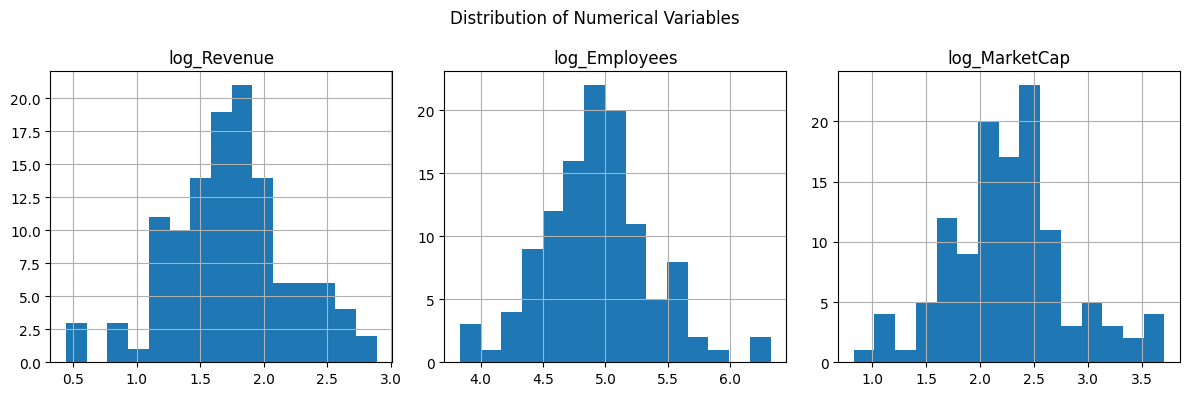

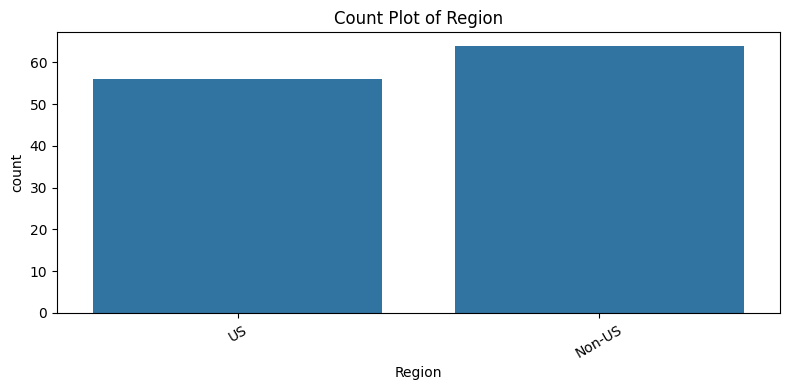

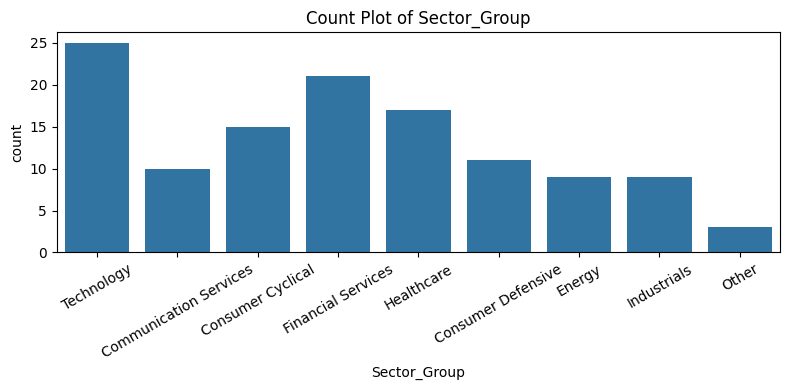

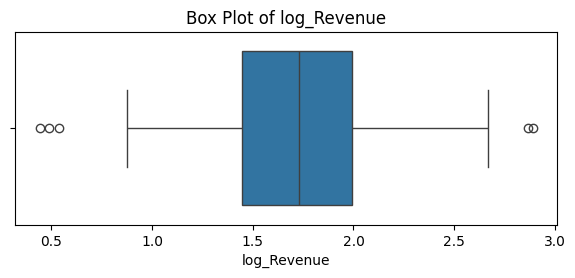

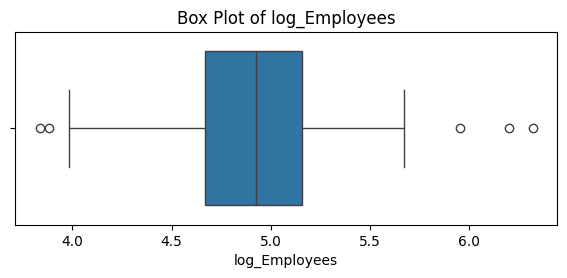

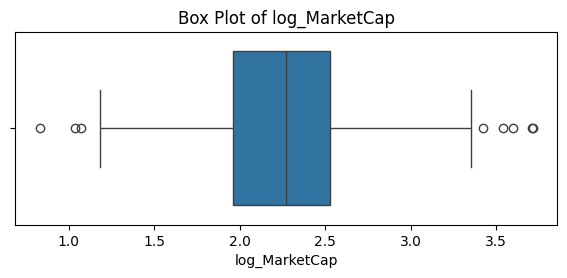

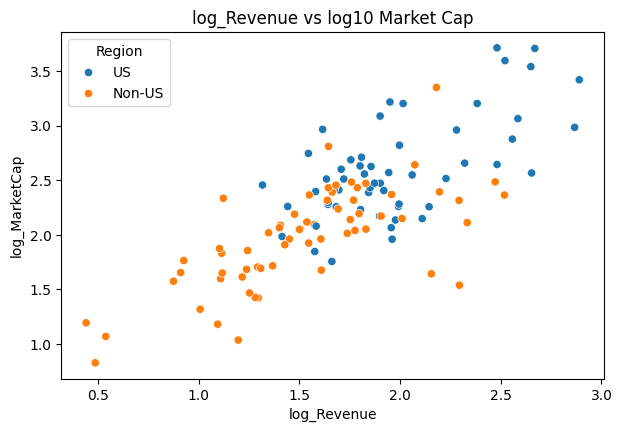

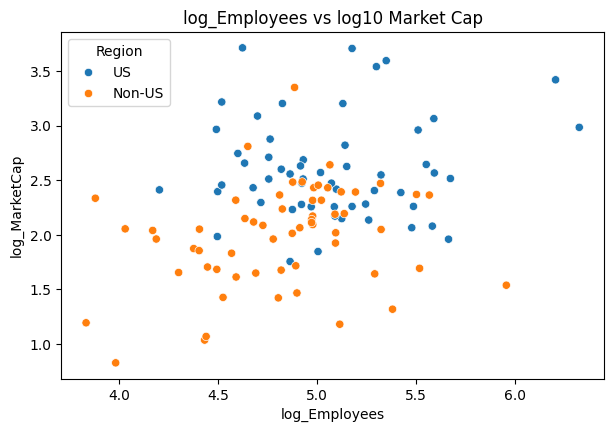

In [76]:
# Distribution plots
mc[numerical].hist(figsize=(12, 4), bins=15, layout=(1, 3))
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

# Categorical count plots
for col in categorical:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=mc, x=col)
    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Box plots
for col in numerical:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=mc[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

# Scatter plots against the target
for col in ["log_Revenue", "log_Employees"]:
    plt.figure(figsize=(7, 4.5))
    sns.scatterplot(data=mc, x=col, y="log_MarketCap", hue="Region")
    plt.title(f"{col} vs log10 Market Cap")
    plt.show()

Encoded Dataset:


,log_Revenue,log_Employees,log_MarketCap,Region_US,Sector_Group_Consumer Cyclical,Sector_Group_Consumer Defensive,Sector_Group_Energy,Sector_Group_Financial Services,Sector_Group_Healthcare,Sector_Group_Industrials,Sector_Group_Other,Sector_Group_Technology
0,2.669152,5.176091,3.706893,1,0,0,0,0,0,0,0,1
1,2.520927,5.348305,3.595119,1,0,0,0,0,0,0,0,1
2,2.649204,5.298707,3.540467,1,0,0,0,0,0,0,0,0
3,2.889683,6.202761,3.419889,1,1,0,0,0,0,0,0,0
4,2.481400,4.623249,3.712586,1,0,0,0,0,0,0,0,1


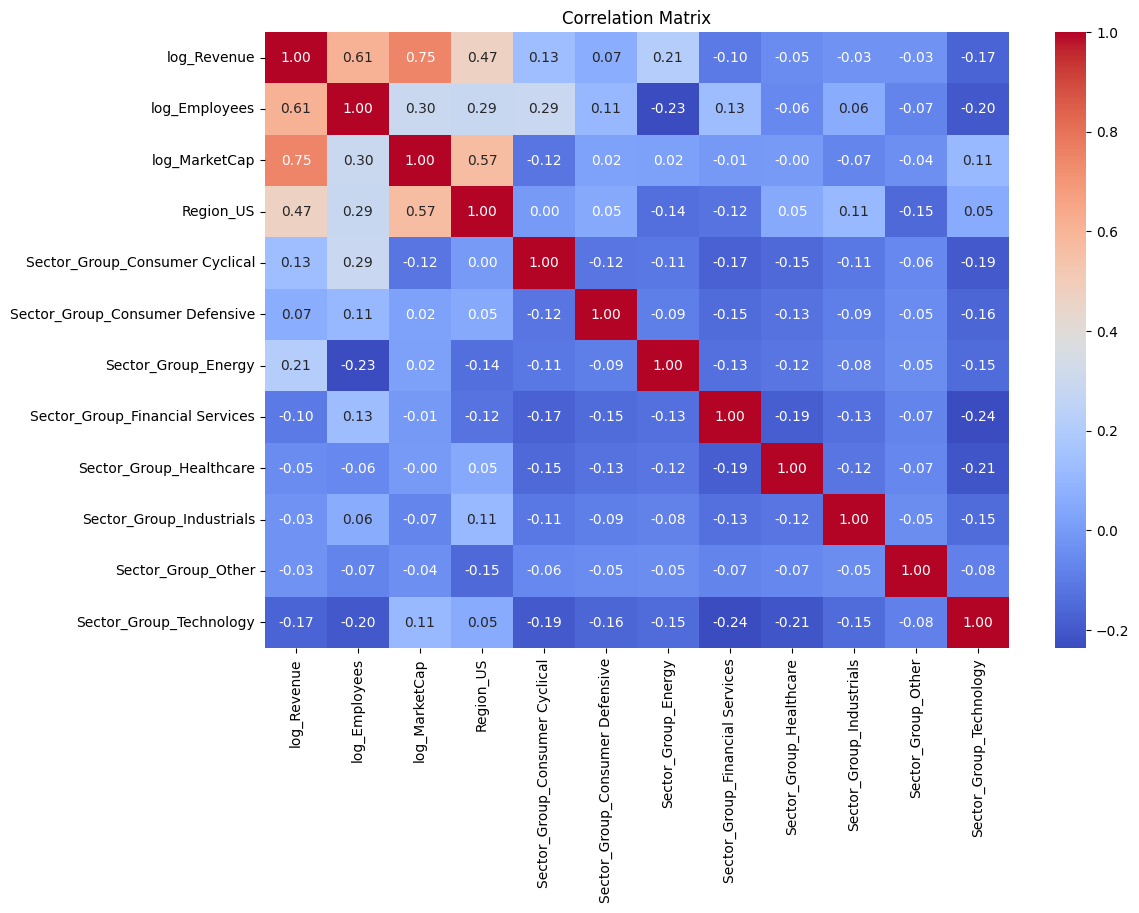

Covariance Matrix:


,log_Revenue,log_Employees,log_MarketCap,Region_US,Sector_Group_Consumer Cyclical,Sector_Group_Consumer Defensive,Sector_Group_Energy,Sector_Group_Financial Services,Sector_Group_Healthcare,Sector_Group_Industrials,Sector_Group_Other,Sector_Group_Technology
log_Revenue,0.227,0.125,0.198,0.113,0.021,0.009,0.027,-0.019,-0.009,-0.004,-0.002,-0.032
log_Employees,0.125,0.192,0.072,0.063,0.043,0.014,-0.027,0.021,-0.009,0.007,-0.005,-0.037
log_MarketCap,0.198,0.072,0.305,0.157,-0.021,0.004,0.002,-0.002,-0.000,-0.010,-0.004,0.026
Region_US,0.113,0.063,0.157,0.251,0.000,0.007,-0.018,-0.024,0.009,0.015,-0.012,0.011
Sector_Group_Consumer Cyclical,0.021,0.043,-0.021,0.000,0.110,-0.012,-0.009,-0.022,-0.018,-0.009,-0.003,-0.026
Sector_Group_Consumer Defensive,0.009,0.014,0.004,0.007,-0.012,0.084,-0.007,-0.016,-0.013,-0.007,-0.002,-0.019
Sector_Group_Energy,0.027,-0.027,0.002,-0.018,-0.009,-0.007,0.070,-0.013,-0.011,-0.006,-0.002,-0.016
Sector_Group_Financial Services,-0.019,0.021,-0.002,-0.024,-0.022,-0.016,-0.013,0.146,-0.025,-0.013,-0.004,-0.037
Sector_Group_Healthcare,-0.009,-0.009,-0.000,0.009,-0.018,-0.013,-0.011,-0.025,0.123,-0.011,-0.004,-0.030
Sector_Group_Industrials,-0.004,0.007,-0.010,0.015,-0.009,-0.007,-0.006,-0.013,-0.011,0.070,-0.002,-0.016


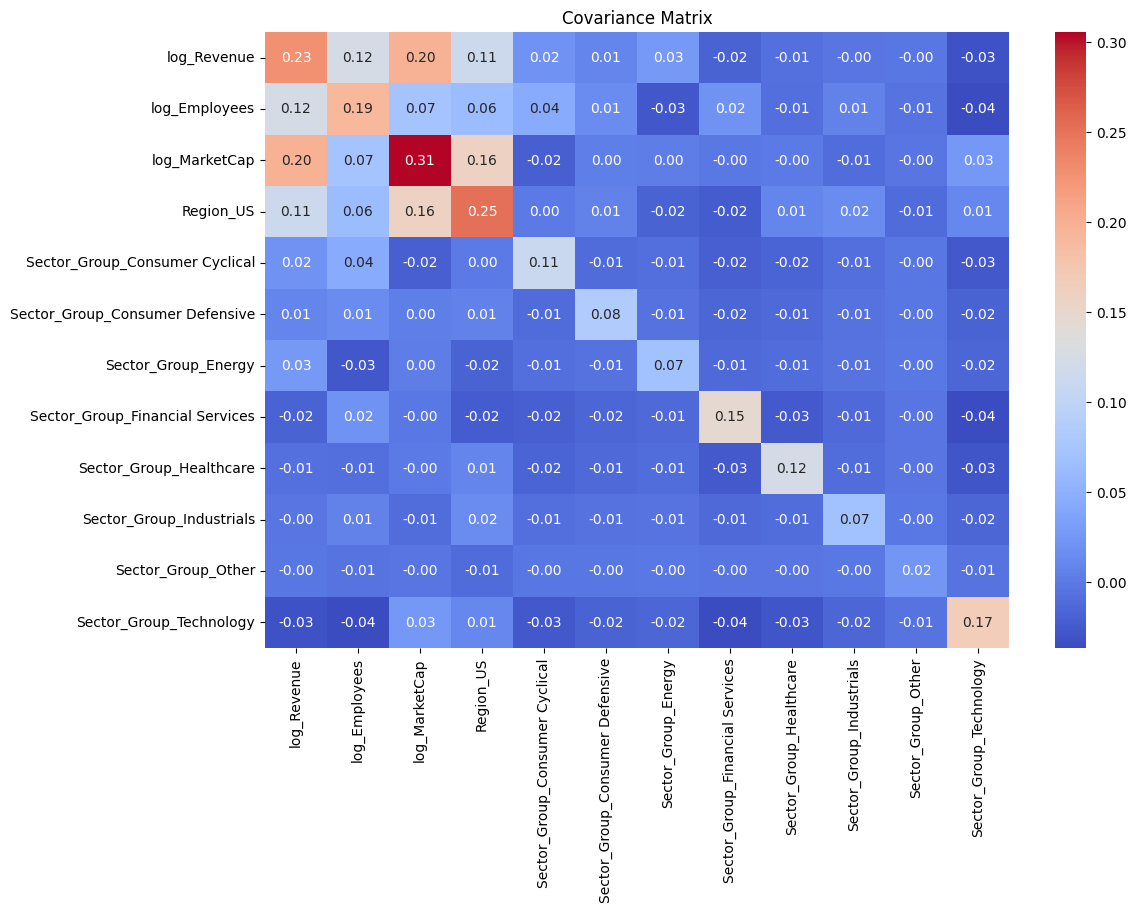

In [77]:
# Remove duplicates (missing values are handled inside the pipeline, fitted on training data only)
mc = mc.drop_duplicates().copy()

# Convert categorical variables to numbers (only for correlation and covariance analysis)
mc_encoded = pd.get_dummies(mc, columns=categorical, drop_first=True, dtype=int)
print("Encoded Dataset:")
display(mc_encoded.head())

# Correlation analysis
correlation = mc_encoded.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# Covariance analysis
covariance = mc_encoded.cov()
print("Covariance Matrix:")
display(covariance.round(3))
plt.figure(figsize=(12, 8))
sns.heatmap(covariance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Covariance Matrix")
plt.show()

In [78]:
# Separate Features and Target
X = mc.drop("log_MarketCap", axis=1)
y = mc["log_MarketCap"]

# Identify Feature Types
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Preprocessing Pipeline
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define Models
models = {
    "Baseline (predict the mean)": DummyRegressor(strategy="mean"),
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.05, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

trained_models = {}
results = []

# Train and Evaluate Models
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    trained_models[name] = pipeline
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
print("Model Evaluation Results:")
display(results_df)

Model Evaluation Results:


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline (predict the mean),0.432316,0.343429,0.586028,-0.126839
1,Multiple Linear Regression,0.220492,0.067132,0.259098,0.779731
2,Ridge Regression,0.225942,0.066426,0.257733,0.782046
3,Lasso Regression,0.306416,0.144415,0.380020,0.526153
4,Decision Tree,0.337061,0.183890,0.428824,0.396631
5,Random Forest,0.325631,0.157277,0.396581,0.483953


,Model,MAE,MSE,RMSE,R2 Score
2,Ridge Regression,0.225942,0.066426,0.257733,0.782046
1,Multiple Linear Regression,0.220492,0.067132,0.259098,0.779731
3,Lasso Regression,0.306416,0.144415,0.380020,0.526153
5,Random Forest,0.325631,0.157277,0.396581,0.483953
4,Decision Tree,0.337061,0.183890,0.428824,0.396631
0,Baseline (predict the mean),0.432316,0.343429,0.586028,-0.126839


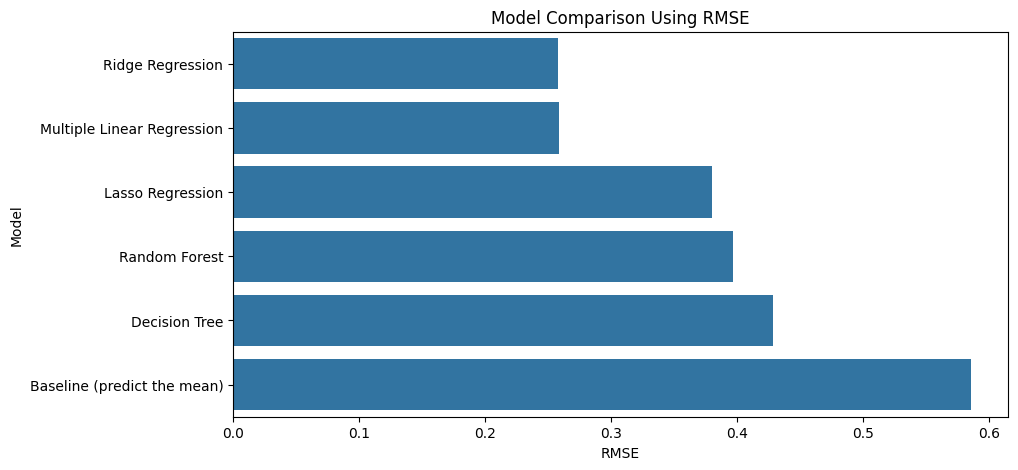

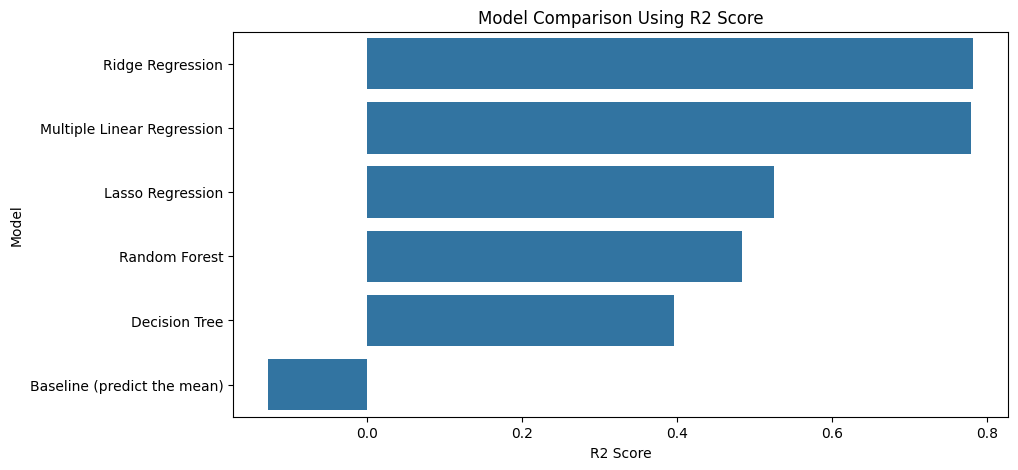

Best Model: Ridge Regression


In [79]:
# Sort Models by RMSE
results_df = results_df.sort_values("RMSE")
display(results_df)

# Compare RMSE
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="RMSE", y="Model")
plt.title("Model Comparison Using RMSE")
plt.show()

# Compare R2 Score
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="R2 Score", y="Model")
plt.title("Model Comparison Using R2 Score")
plt.show()

# Select Best Model (the baseline is only a yardstick, so it is not a candidate)
best_model_name = results_df[results_df["Model"] != "Baseline (predict the mean)"].iloc[0]["Model"]
best_pipeline = trained_models[best_model_name]
print("Best Model:", best_model_name)

Best Model Saved Successfully!


,Actual (log10),Predicted (log10),Actual (USD B),Predicted (USD B)
0,1.76,2.17,57.07,147.95
1,2.51,2.28,324.81,192.31
2,3.71,3.44,5159.25,2724.55
3,2.51,2.27,324.97,186.87
4,2.63,2.66,428.13,454.85
5,2.39,2.13,246.95,136.26
6,2.37,2.05,234.54,111.23
7,2.98,3.09,964.92,1233.24
8,2.47,2.71,297.35,509.93
9,1.32,1.46,20.88,29.07


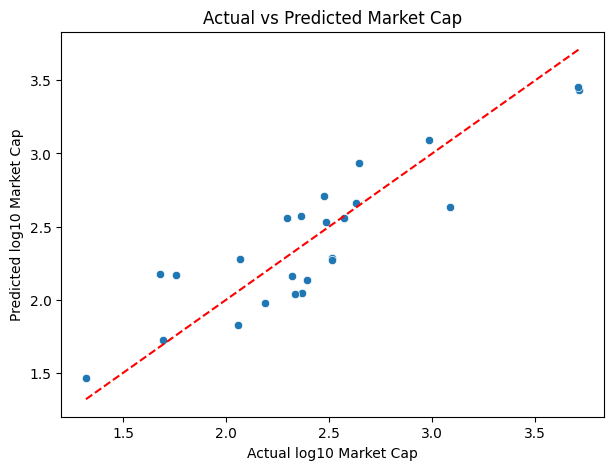

In [80]:
# Save Best Model
joblib.dump(best_pipeline, "marketcap_regression_pipeline.joblib")
print("Best Model Saved Successfully!")

# Load Model
loaded_model = joblib.load("marketcap_regression_pipeline.joblib")

# Actual vs Predicted
y_pred = loaded_model.predict(X_test)
comparison = pd.DataFrame({
    "Actual (log10)": y_test.values,
    "Predicted (log10)": y_pred,
    "Actual (USD B)": 10 ** y_test.values,
    "Predicted (USD B)": 10 ** y_pred
})
display(comparison.head(10).round(2))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual log10 Market Cap")
plt.ylabel("Predicted log10 Market Cap")
plt.title("Actual vs Predicted Market Cap")
plt.show()

---
# Practical No. 08-C: Classification

**AIM:** predict whether a company is in the **High market-cap tier** (top third by market cap) from its revenue, employees, region and sector.

- Target `High_Cap`: 1 = High tier, 0 = Low or Medium tier
- Market cap is *not* used as a feature (it would give the answer away)
- A baseline that always predicts the majority class is added as a yardstick

Class counts (1 = High tier):
High_Cap
0    80
1    40
Name: count, dtype: int64


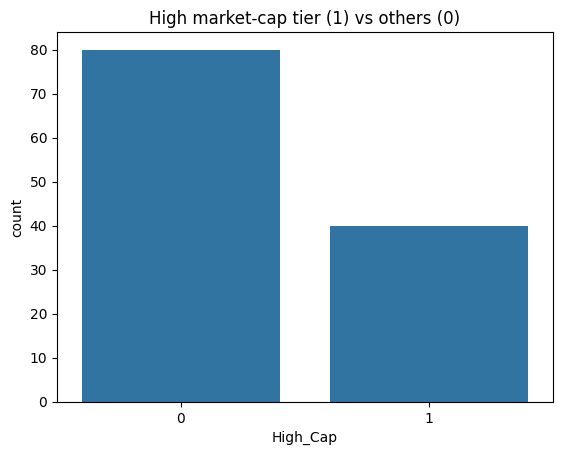


Correlation of numeric features with High_Cap:
log_Revenue      0.517
log_Employees    0.201
Name: High_Cap, dtype: float64


In [81]:
clf_data = df[["log_Revenue", "log_Employees", "Region", "Sector_Group"]].copy()
clf_data["High_Cap"] = (df["Cap_Tier"] == "High").astype(int)

print("Class counts (1 = High tier):")
print(clf_data["High_Cap"].value_counts())

sns.countplot(x="High_Cap", data=clf_data)
plt.title("High market-cap tier (1) vs others (0)")
plt.show()

print("\nCorrelation of numeric features with High_Cap:")
print(clf_data[["log_Revenue", "log_Employees", "High_Cap"]].corr()["High_Cap"].drop("High_Cap").round(3))

In [82]:
Xc = clf_data.drop(columns="High_Cap")
yc = clf_data["High_Cap"]

# 80-20 split; stratify keeps the same share of High-tier companies in train and test
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print("Training data:", Xc_train.shape, "| Testing data:", Xc_test.shape)
print("High-tier companies in test set:", int(yc_test.sum()), "of", len(yc_test))

Training data: (96, 4) | Testing data: (24, 4)
High-tier companies in test set: 8 of 24


--- Metrics for Baseline (most frequent) on Test Set ---
Accuracy : 0.6667
Precision: 0.0000
Recall   : 0.0000
F1-Score : 0.0000
              precision    recall  f1-score   support

           0       0.67      1.00      0.80        16
           1       0.00      0.00      0.00         8

    accuracy                           0.67        24
   macro avg       0.33      0.50      0.40        24
weighted avg       0.44      0.67      0.53        24

--- Metrics for Logistic Regression on Test Set ---
Accuracy : 0.8333
Precision: 0.8333
Recall   : 0.6250
F1-Score : 0.7143
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        16
           1       0.83      0.62      0.71         8

    accuracy                           0.83        24
   macro avg       0.83      0.78      0.80        24
weighted avg       0.83      0.83      0.83        24

--- Metrics for Decision Tree on Test Set ---
Accuracy : 0.7917
Precision: 0.6364
Recall   : 

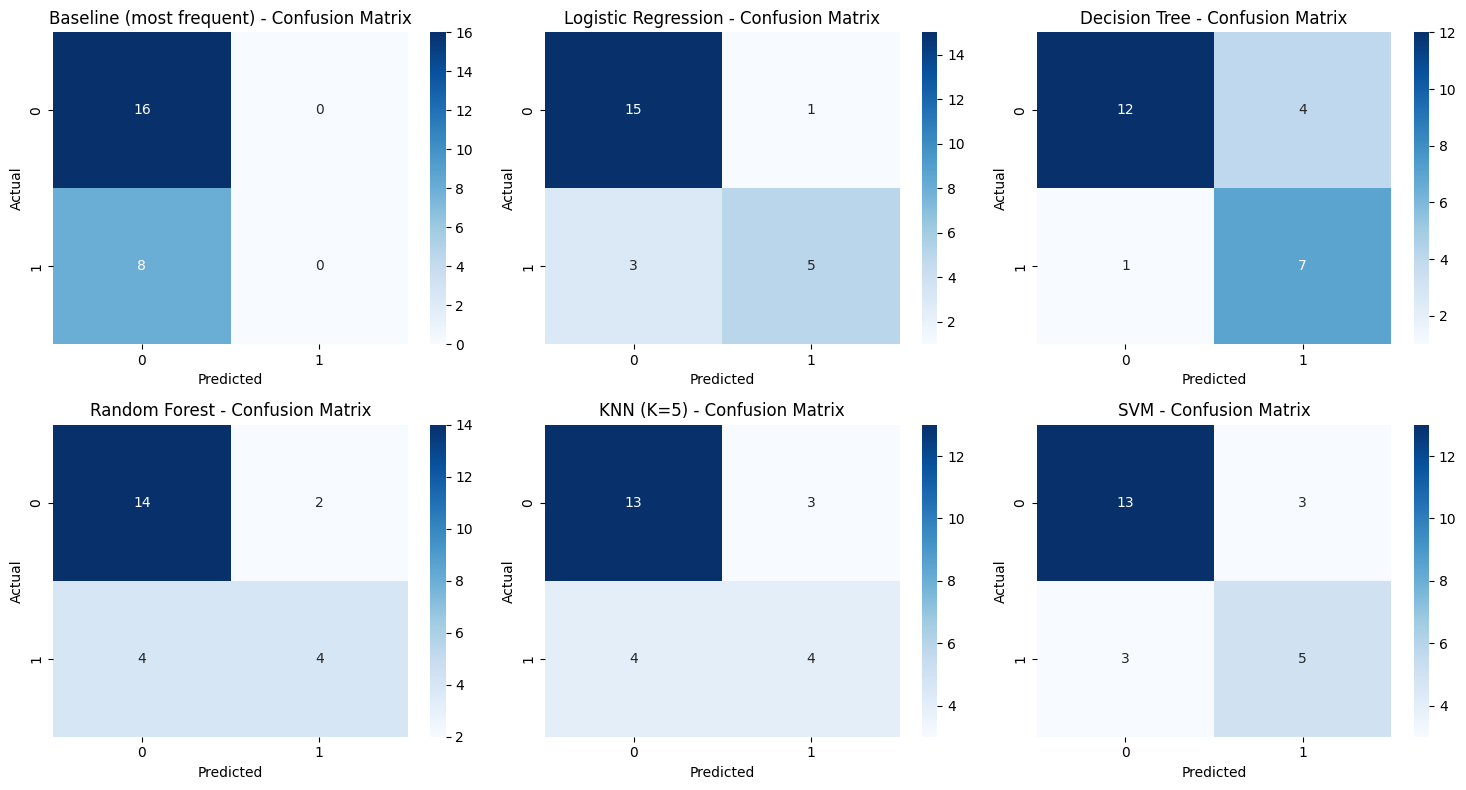

In [83]:
clf_models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN (K=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42)
}

clf_pipelines = {}
clf_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, (name, clf) in zip(axes, clf_models.items()):
    pipe = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clf)
    ])
    pipe.fit(Xc_train, yc_train)
    pred = pipe.predict(Xc_test)
    clf_pipelines[name] = pipe

    print(f"--- Metrics for {name} on Test Set ---")
    print(f"Accuracy : {accuracy_score(yc_test, pred):.4f}")
    print(f"Precision: {precision_score(yc_test, pred, zero_division=0):.4f}")
    print(f"Recall   : {recall_score(yc_test, pred, zero_division=0):.4f}")
    print(f"F1-Score : {f1_score(yc_test, pred, zero_division=0):.4f}")
    print(classification_report(yc_test, pred, zero_division=0))

    sns.heatmap(confusion_matrix(yc_test, pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    clf_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision": precision_score(yc_test, pred, zero_division=0),
        "Recall": recall_score(yc_test, pred, zero_division=0),
        "F1-Score": f1_score(yc_test, pred, zero_division=0)
    })

plt.tight_layout()
plt.show()

--- Model Comparison Table ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline (most frequent),0.6667,0.0000,0.000,0.0000
1,Logistic Regression,0.8333,0.8333,0.625,0.7143
2,Decision Tree,0.7917,0.6364,0.875,0.7368
3,Random Forest,0.7500,0.6667,0.500,0.5714
4,KNN (K=5),0.7083,0.5714,0.500,0.5333
5,SVM,0.7500,0.6250,0.625,0.6250


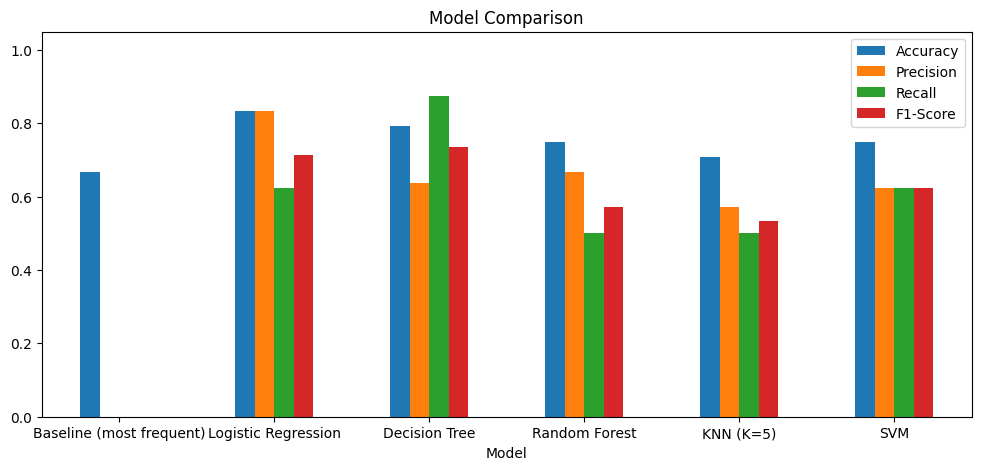

Best model: Decision Tree


In [84]:
comparison_df = pd.DataFrame(clf_rows)
print("--- Model Comparison Table ---")
display(comparison_df.round(4))

comparison_df.set_index("Model").plot(kind="bar", figsize=(12, 5), ylim=(0, 1.05))
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.show()

# Best model = highest F1-Score (the baseline is only a yardstick, so it is not a candidate)
candidates = comparison_df[comparison_df["Model"] != "Baseline (most frequent)"]
best_row = candidates.sort_values(by=["F1-Score", "Recall"], ascending=False).iloc[0]
best_name = best_row["Model"]
best_clf = clf_pipelines[best_name]
print("Best model:", best_name)

### Justification
In the cancer practical, Recall was the key metric because a missed case is costly. Here no error is much worse than the other, so **F1-Score** (a balance of precision and recall) is used. The test set is small, so the ranking can change with a different split.

In [85]:
# Save the best model (the pipeline already contains the preprocessing, so no separate scaler file is needed)
joblib.dump(best_clf, "marketcap_classifier.joblib")
print("Saved: marketcap_classifier.joblib")

# Check that the saved model loads and works
loaded_clf = joblib.load("marketcap_classifier.joblib")
y_check = loaded_clf.predict(Xc_test)
print("Accuracy of loaded model:", accuracy_score(yc_test, y_check))

Saved: marketcap_classifier.joblib
Accuracy of loaded model: 0.7916666666666666


### Prediction Interface
Enter a company's revenue, employees, region and sector to see whether the model puts it in the High market-cap tier.

In [86]:
classifier = joblib.load("marketcap_classifier.joblib")
known_sectors = sorted(df["Sector_Group"].unique())
print("Sectors the model knows:", known_sectors)

def predict_cap_tier(revenue_b, employees, region, sector):
    if revenue_b <= 0 or employees <= 0:
        return "Enter positive values for revenue and employees."
    if region not in ("US", "Non-US"):
        return "Region must be 'US' or 'Non-US'."
    sector = sector if sector in known_sectors else "Other"
    row = pd.DataFrame([{
        "log_Revenue": np.log10(revenue_b),
        "log_Employees": np.log10(employees),
        "Region": region,
        "Sector_Group": sector,
    }])
    label = "High market-cap tier" if classifier.predict(row)[0] == 1 else "Not in the high tier"
    if hasattr(classifier, "predict_proba"):
        label += f" (probability of high tier: {classifier.predict_proba(row)[0][1]:.0%})"
    return label

example_sector = known_sectors[0]
print(predict_cap_tier(400, 150000, "US", example_sector))
print(predict_cap_tier(20, 30000, "Non-US", example_sector))

Sectors the model knows: ['Communication Services', 'Consumer Cyclical', 'Consumer Defensive', 'Energy', 'Financial Services', 'Healthcare', 'Industrials', 'Other', 'Technology']
High market-cap tier (probability of high tier: 100%)
Not in the high tier (probability of high tier: 0%)


In [87]:
# Interface 1: type the values yourself (set RUN_INTERACTIVE = True to use it)
RUN_INTERACTIVE = False

if RUN_INTERACTIVE:
    rev = float(input("Revenue (USD billion): "))
    emp = float(input("Employees: "))
    reg = input("Region (US / Non-US): ")
    sec = input("Sector (" + ", ".join(known_sectors) + "): ")
    print(predict_cap_tier(rev, emp, reg, sec))

---
# Part C: Key Findings and Limitations

In [88]:
print("KEY FINDINGS (printed from the results above)\n")
print("1. Data:", len(df), "listed companies from", df["Country"].nunique(), "countries and", df["Sector"].nunique(), "sectors")
print("2. Market cap is very right-skewed: mean", round(data.mean()), "vs median", round(data.median()), "(USD billion), so the log10 scale is used")
print("3. US vs Non-US: a typical US company is", round(10 ** diff_mean, 2), "times the size of a Non-US one, p-value =", round(p_two_sample, 4))
print("4. Sectors: ANOVA p-value =", round(p_anova, 4))
print("5. Region vs market-cap tier: chi-square p-value =", round(p_chi, 4))
print("6. Revenue vs market cap (log10): correlation =", round(Pearson_r_log, 2), "| R2 of the log regression =", round(ols_model.rsquared, 2))

reg_best = results_df[results_df["Model"] != "Baseline (predict the mean)"].iloc[0]
reg_base = results_df[results_df["Model"] == "Baseline (predict the mean)"].iloc[0]
print("7. Regression: best model", reg_best["Model"], "has test R2 =", round(reg_best["R2 Score"], 2), "| baseline R2 =", round(reg_base["R2 Score"], 2))

clf_base = comparison_df[comparison_df["Model"] == "Baseline (most frequent)"].iloc[0]
print("8. Classification: best model", best_name, "has F1 =", round(best_row["F1-Score"], 2), "| baseline F1 =", round(clf_base["F1-Score"], 2))

KEY FINDINGS (printed from the results above)

1. Data: 120 listed companies from 20 countries and 9 sectors
2. Market cap is very right-skewed: mean 445 vs median 186 (USD billion), so the log10 scale is used
3. US vs Non-US: a typical US company is 4.23 times the size of a Non-US one, p-value = 0.0
4. Sectors: ANOVA p-value = 0.8579
5. Region vs market-cap tier: chi-square p-value = 0.0
6. Revenue vs market cap (log10): correlation = 0.75 | R2 of the log regression = 0.57
7. Regression: best model Ridge Regression has test R2 = 0.78 | baseline R2 = -0.13
8. Classification: best model Decision Tree has F1 = 0.74 | baseline F1 = 0.0


### Limitations
- **Selection bias:** the companies are large ones that exist today, mostly US-listed or ADRs. Findings describe this sample, not "all listed companies".
- **Timing and currency:** market cap is a current snapshot, revenue is trailing twelve months in the reporting currency, and both are converted at one recent exchange rate.
- **Few predictors:** the models use only revenue, employees, region and sector. Market value mostly reflects profit, growth and risk, which are not included, so weak predictions are expected.
- **Small groups and small test sets:** some country, sector and region groups hold only a few companies, and every test set is small, so p-values and scores are noisy.
- **Many tests:** with many hypothesis tests at the 5% level, a few "significant" results can happen by chance.
- **Association, not causation:** nothing here shows that revenue or region *causes* a larger market cap.

### Future work
Add profit margin, growth and P/E ratio as features, use several time snapshots, and draw companies from an index instead of hand-picking.

---
# Part D: Streamlit Dashboard (Model Comparison)

This part turns the results above into an interactive dashboard with 5 pages:

| Page | What it shows |
|---|---|
| **Overview** | Key numbers, the best regression and classification model, top companies, market cap by sector, country and region |
| **Data Explorer** | Filter companies by sector, region and market cap, then see the scatter plot, histogram and table |
| **Regression Models** | All models compared on R², RMSE, MAE and MSE, the best one highlighted, actual vs predicted, errors, and which features matter |
| **Classification Models** | All classifiers compared on accuracy, precision, recall and F1, the best one highlighted, and a confusion matrix for each |
| **Try a Prediction** | Enter a company's revenue, employees, region and sector and see what every model predicts |

**How to run it in Colab:** run the next 4 cells in order.
1. Save the results the dashboard needs
2. Install Streamlit
3. Write the dashboard file `app.py`
4. Start the dashboard and open the public link

**If you change the models above, run step 1 again** so the dashboard shows the new results.

In [89]:
# Step 1: save everything the dashboard needs
df.to_csv("dashboard_data.csv", index=False)

# Regression results (Practical 8-B). "Best" marks the model chosen above (the baseline is never chosen).
results_df["Best"] = results_df["Model"] == best_model_name
results_df.to_csv("dashboard_regression_results.csv", index=False)

# Actual vs predicted market cap (log10) on the test set, for every model
pred_rows = []
for name, pipe in trained_models.items():
    pred = pipe.predict(X_test)
    for ticker, actual, predicted in zip(df.loc[y_test.index, "Ticker"], y_test, pred):
        pred_rows.append({"Model": name, "Ticker": ticker, "Actual": actual, "Predicted": predicted})
pd.DataFrame(pred_rows).to_csv("dashboard_regression_predictions.csv", index=False)

# Which features matter: coefficients (linear models) or importances (tree models)
imp_rows = []
for name, pipe in trained_models.items():
    feature_names = pipe.named_steps["preprocessing"].get_feature_names_out()
    m = pipe.named_steps["model"]
    if hasattr(m, "coef_"):
        values = m.coef_
    elif hasattr(m, "feature_importances_"):
        values = m.feature_importances_
    else:
        continue
    for f, v in zip(feature_names, values):
        imp_rows.append({"Model": name, "Feature": f, "Value": v})
pd.DataFrame(imp_rows).to_csv("dashboard_feature_importance.csv", index=False)

# Classification results (Practical 8-C)
comparison_df["Best"] = comparison_df["Model"] == best_name
comparison_df.to_csv("dashboard_classification_results.csv", index=False)

cm_rows = []
for name, pipe in clf_pipelines.items():
    tn, fp, fn, tp = confusion_matrix(yc_test, pipe.predict(Xc_test), labels=[0, 1]).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
pd.DataFrame(cm_rows).to_csv("dashboard_confusion_matrices.csv", index=False)

# All trained models, so the dashboard can compare their predictions
joblib.dump(trained_models, "all_regression_models.joblib")
joblib.dump(clf_pipelines, "all_classifiers.joblib")
print("Dashboard files saved.")

Dashboard files saved.


In [90]:
# Step 2: install Streamlit (Plotly is already installed in Colab)
!pip install -q streamlit plotly

In [91]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import joblib

# Set page configuration
st.set_page_config(
    page_title="Global Market Cap Dashboard",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Load preprocessed datasets saved for the dashboard
@st.cache_data
def load_data():
    df = pd.read_csv("dashboard_data.csv")
    reg_results = pd.read_csv("dashboard_regression_results.csv")
    reg_pred = pd.read_csv("dashboard_regression_predictions.csv")
    feature_imp = pd.read_csv("dashboard_feature_importance.csv")
    clf_results = pd.read_csv("dashboard_classification_results.csv")
    confusion_matrices = pd.read_csv("dashboard_confusion_matrices.csv")
    return df, reg_results, reg_pred, feature_imp, clf_results, confusion_matrices

try:
    df, reg_results, reg_pred, feature_imp, clf_results, confusion_matrices = load_data()
except Exception as e:
    st.error(f"Error loading dashboard files: {e}. Please ensure you ran Step 1 first!")
    st.stop()

# Load saved pipelines
try:
    all_reg_models = joblib.load("all_regression_models.joblib")
    all_clf_models = joblib.load("all_classifiers.joblib")
except Exception as e:
    st.warning(f"Could not load trained model files: {e}. Try a Prediction page might not work.")

# Sidebar Navigation
st.sidebar.title("Dashboard Navigation")
page = st.sidebar.radio("Go to", ["Overview", "Data Explorer", "Regression Models", "Classification Models", "Try a Prediction"])

# Helper formatting function
def money_billions(val):
    if pd.isna(val):
        return "N/A"
    return f"${val:,.1f} B"

def add_chart_layout(fig, height=400):
    fig.update_layout(
        height=height,
        margin=dict(l=20, r=20, t=40, b=20),
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)"
    )
    return fig

# Extract metrics for Overview snapshot
best_reg = reg_results[reg_results["Best"] == True].iloc[0] if not reg_results.empty else None
base_reg = reg_results[reg_results["Model"].str.contains("Baseline", na=False)].iloc[0] if not reg_results.empty else None
best_clf = clf_results[clf_results["Best"] == True].iloc[0] if not clf_results.empty else None
base_clf = clf_results[clf_results["Model"].str.contains("Baseline", na=False)].iloc[0] if not clf_results.empty else None

colors = {"Other": "#3182bd", "Baseline": "#9ecae1", "Best": "#ff7f0e"}

st.title("Global Companies Market Capitalization Analysis")
st.caption("Market-cap analysis, model evaluation and interactive predictions · Source: Yahoo Finance (yfinance)")

# ---------------------------------------------------------------------
# 1. OVERVIEW
# ---------------------------------------------------------------------
if page == "Overview":
    st.subheader("Market overview")
    valid_caps = df["MarketCap_B"].dropna()
    largest = df.loc[df["MarketCap_B"].idxmax()] if not valid_caps.empty else None

    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Companies", f"{len(df):,}")
    c2.metric("Countries", f"{df['Country'].nunique():,}")
    c3.metric("Sectors", f"{df['Sector'].nunique():,}")
    c4.metric("Median market cap", money_billions(valid_caps.median() if not valid_caps.empty else np.nan))
    c5.metric("Largest company", str(largest["Ticker"]) if largest is not None else "N/A",
              help=money_billions(largest["MarketCap_B"]) if largest is not None else None)

    st.markdown("### Model snapshot")
    left, right = st.columns(2)
    with left:
        st.markdown("#### Regression")
        if best_reg is not None:
            st.metric("Selected model", str(best_reg["Model"]))
            m1, m2 = st.columns(2)
            m1.metric("R² score", f"{best_reg['R2 Score']:.3f}")
            m2.metric("RMSE · log scale", f"{best_reg['RMSE']:.3f}")
            if base_reg is not None:
                st.caption(f"Mean-prediction baseline R²: {base_reg['R2 Score']:.3f}")
    with right:
        st.markdown("#### Classification")
        if best_clf is not None:
            st.metric("Selected model", str(best_clf["Model"]))
            m1, m2 = st.columns(2)
            m1.metric("F1-score", f"{best_clf['F1-Score']:.3f}")
            m2.metric("Accuracy", f"{best_clf['Accuracy']:.3f}")
            if base_clf is not None:
                st.caption(f"Majority-class baseline F1: {base_clf['F1-Score']:.3f}")

    st.divider()
    left, right = st.columns(2)
    top_n = df.dropna(subset=["MarketCap_B"]).nlargest(10, "MarketCap_B").sort_values("MarketCap_B")
    if not top_n.empty:
        fig = px.bar(top_n, x="MarketCap_B", y="Company", color="Sector", orientation="h",
                     hover_data=["Ticker", "Country"], title="Top 10 companies by market cap")
        left.plotly_chart(add_chart_layout(fig), use_container_width=True)
    sector_data = df.dropna(subset=["MarketCap_B"])
    if not sector_data.empty:
        fig = px.box(sector_data, x="Sector", y="MarketCap_B", color="Sector", log_y=True,
                     points="outliers", hover_name="Company", title="Market cap by sector · log scale")
        fig.update_layout(showlegend=False, xaxis_tickangle=-25)
        right.plotly_chart(add_chart_layout(fig), use_container_width=True)

    left, right = st.columns(2)
    country_counts = df["Country"].fillna("Unknown").value_counts().head(10).rename_axis("Country").reset_index(name="Companies")
    fig = px.bar(country_counts, x="Country", y="Companies", title="Companies by country · top 10")
    left.plotly_chart(add_chart_layout(fig, 360), use_container_width=True)

    region_cap = df.dropna(subset=["Region", "MarketCap_B"]).groupby("Region", as_index=False)["MarketCap_B"].sum()
    if not region_cap.empty:
        fig = px.pie(region_cap, names="Region", values="MarketCap_B", hole=0.48,
                     title="Share of total market cap by region")
        right.plotly_chart(add_chart_layout(fig, 360), use_container_width=True)

    with st.expander("Data notes and limitations"):
        st.markdown(
            "- This is a sample of large companies that exist today; it does not represent every listed company.\n"
            "- Market cap is a snapshot, while revenue is trailing-twelve-month revenue converted to USD.\n"
            "- The models use revenue, employee count, region and sector. Profitability, growth and risk are not included.\n"
            "- The test sets are small, so model scores and rankings can vary with a different split.\n"
            "- Predictions are educational estimates, not investment advice."
        )

# ---------------------------------------------------------------------
# 2. DATA EXPLORER
# ---------------------------------------------------------------------
elif page == "Data Explorer":
    st.subheader("Explore the company dataset")
    st.write("Filter the sample and inspect company-level figures.")

    all_sectors = sorted(df["Sector"].dropna().astype(str).unique().tolist())
    all_regions = sorted(df["Region"].dropna().astype(str).unique().tolist())
    valid_caps = df["MarketCap_B"].dropna()
    if valid_caps.empty:
        st.warning("No valid market-cap values are available to filter.")
        st.stop()

    c1, c2, c3 = st.columns([1.3, 1, 1.6])
    selected_sectors = c1.multiselect("Sector", all_sectors, default=all_sectors)
    selected_regions = c2.multiselect("Region", all_regions, default=all_regions)
    min_cap, max_cap = float(valid_caps.min()), float(valid_caps.max())
    if min_cap == max_cap:
        cap_range = (min_cap, max_cap)
        c3.caption(f"Market cap: {money_billions(min_cap)}")
    else:
        cap_range = c3.slider("Market cap range (USD B)", min_cap, max_cap, (min_cap, max_cap))

    filtered = df[
        df["Sector"].astype(str).isin(selected_sectors)
        & df["Region"].astype(str).isin(selected_regions)
        & df["MarketCap_B"].between(cap_range[0], cap_range[1])
    ].copy()

    st.info(f"**{len(filtered):,}** of **{len(df):,}** companies match the selected filters.")
    if filtered.empty:
        st.warning("No companies match these filters. Try selecting more sectors, regions or a wider market-cap range.")
    else:
        c1, c2, c3 = st.columns(3)
        c1.metric("Average market cap", money_billions(filtered["MarketCap_B"].mean()))
        c2.metric("Median market cap", money_billions(filtered["MarketCap_B"].median()))
        ps = filtered["PS_Ratio"].median()
        c3.metric("Median price-to-sales", f"{ps:.2f}" if pd.notna(ps) else "N/A")

        left, right = st.columns(2)
        scatter_data = filtered.dropna(subset=["Revenue_B", "MarketCap_B"])
        scatter_data = scatter_data[(scatter_data["Revenue_B"] > 0) & (scatter_data["MarketCap_B"] > 0)]
        if not scatter_data.empty:
            fig = px.scatter(scatter_data, x="Revenue_B", y="MarketCap_B", color="Sector",
                             hover_name="Company", hover_data=["Ticker", "Country"], log_x=True, log_y=True,
                             title="Revenue vs market cap · log scales")
            left.plotly_chart(add_chart_layout(fig), use_container_width=True)
        else:
            left.info("There are not enough positive revenue and market-cap values for a log-scale scatter plot.")

        if "log_MarketCap" in filtered.columns:
            fig = px.histogram(filtered.dropna(subset=["log_MarketCap"]), x="log_MarketCap", nbins=20,
                               title="Distribution of log10 market cap")
            right.plotly_chart(add_chart_layout(fig), use_container_width=True)

        st.markdown("### Company records")
        search = st.text_input("Search company, ticker or country", placeholder="e.g. Apple, AAPL, United States")
        table = filtered.copy()
        if search.strip():
            mask = pd.Series(False, index=table.index)
            for col in ["Company", "Ticker", "Country"]:
                mask |= table[col].astype(str).str.contains(search.strip(), case=False, na=False)
            table = table[mask]
        display_cols = ["Company", "Ticker", "Country", "Region", "Sector", "MarketCap_B", "Revenue_B", "PS_Ratio", "Employees"]
        st.dataframe(table[display_cols].round(2), use_container_width=True, hide_index=True)
        st.download_button(
            "Download filtered data as CSV",
            data=table[display_cols].to_csv(index=False).encode("utf-8"),
            file_name="filtered_market_cap_companies.csv",
            mime="text/csv",
        )

# ---------------------------------------------------------------------
# 3. REGRESSION MODELS
# ---------------------------------------------------------------------
elif page == "Regression Models":
    st.subheader("Regression model evaluation")
    st.caption("The target is log10 market cap. Higher R² is better; lower RMSE, MAE and MSE are better.")
    if best_reg is not None:
        st.info(f"Best selected model: **{best_reg['Model']}** · selected using the notebook's model-selection process.")

    tab_compare, tab_detail, tab_features = st.tabs(["Compare models", "Prediction errors", "Feature information"])

    with tab_compare:
        metric = st.selectbox("Metric", ["R2 Score", "RMSE", "MAE", "MSE"], key="reg_metric")
        plot_df = reg_results.copy()
        plot_df["Type"] = "Other"
        plot_df.loc[plot_df["Model"].astype(str).str.contains("Baseline", case=False), "Type"] = "Baseline"
        if best_reg is not None:
            plot_df.loc[plot_df["Model"] == best_reg["Model"], "Type"] = "Best"
        plot_df = plot_df.sort_values(metric, ascending=(metric != "R2 Score"))
        fig = px.bar(plot_df, x=metric, y="Model", color="Type", orientation="h",
                     color_discrete_map=colors, title=f"Test-set comparison · {metric}",
                     hover_data=[c for c in ["R2 Score", "RMSE", "MAE", "MSE"] if c != metric])
        st.plotly_chart(add_chart_layout(fig, max(380, 42 * len(plot_df))), use_container_width=True)
        st.dataframe(reg_results.drop(columns=["Best"], errors="ignore").sort_values("RMSE").round(3),
                     use_container_width=True, hide_index=True)
        if base_reg is not None and best_reg is not None and best_reg["R2 Score"] > base_reg["R2 Score"] + 0.05:
            st.success("The selected model's R² is meaningfully higher than the mean-prediction baseline on this test split.")
        else:
            st.warning("The selected model does not clearly outperform the baseline on R². Treat the result cautiously.")

    with tab_detail:
        model_names = reg_results["Model"].astype(str).tolist()
        best_name = str(best_reg["Model"]) if best_reg is not None else ""
        default_index = model_names.index(best_name) if best_name in model_names else 0
        chosen = st.selectbox("Select regression model", model_names, index=default_index, key="reg_detail_model")
        row = reg_results[reg_results["Model"].astype(str) == chosen].iloc[0]
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("R²", f"{row['R2 Score']:.3f}")
        c2.metric("RMSE", f"{row['RMSE']:.3f}")
        c3.metric("MAE", f"{row['MAE']:.3f}")
        c4.metric("MSE", f"{row['MSE']:.3f}")

        model_pred = reg_pred[reg_pred["Model"].astype(str) == chosen].copy()
        if model_pred.empty:
            st.warning("No saved test predictions were found for this model.")
        else:
            model_pred["Error"] = model_pred["Predicted"] - model_pred["Actual"]
            left, right = st.columns(2)
            fig = px.scatter(model_pred, x="Actual", y="Predicted", hover_name="Ticker",
                             title="Actual vs predicted · log10 market cap")
            left.plotly_chart(add_chart_layout(fig), use_container_width=True)
            fig = px.histogram(model_pred, x="Error", nbins=15, title="Residual distribution")
            right.plotly_chart(add_chart_layout(fig), use_container_width=True)

    with tab_features:
        st.markdown("#### Feature Importance / Coefficients")
        reg_models_list = feature_imp["Model"].unique().tolist()
        if not reg_models_list:
            st.info("No coefficients or importances are saved for baseline or non-linear models.")
        else:
            chosen_imp_model = st.selectbox("Model features to view", reg_models_list)
            sub_imp = feature_imp[feature_imp["Model"] == chosen_imp_model].sort_values("Value", key=abs, ascending=False)
            fig = px.bar(sub_imp, x="Value", y="Feature", orientation="h", title=f"Feature significance for {chosen_imp_model}")
            st.plotly_chart(add_chart_layout(fig, max(300, 30 * len(sub_imp))), use_container_width=True)

# ---------------------------------------------------------------------
# 4. CLASSIFICATION MODELS
# ---------------------------------------------------------------------
elif page == "Classification Models":
    st.subheader("Classification model evaluation")
    st.caption("The target is whether a company is in the top-third High Market Cap tier (1 = High, 0 = Low/Medium).")
    if best_clf is not None:
        st.info(f"Best selected model: **{best_clf['Model']}** (selected based on highest F1-Score on test set).")

    tab_clf_compare, tab_clf_matrix = st.tabs(["Compare classifiers", "Confusion matrices"])

    with tab_clf_compare:
        clf_metric = st.selectbox("Metric", ["F1-Score", "Accuracy", "Precision", "Recall"], key="clf_metric_select")
        plot_clf_df = clf_results.copy()
        plot_clf_df["Type"] = "Other"
        plot_clf_df.loc[plot_clf_df["Model"].astype(str).str.contains("Baseline", case=False), "Type"] = "Baseline"
        if best_clf is not None:
            plot_clf_df.loc[plot_clf_df["Model"] == best_clf["Model"], "Type"] = "Best"
        plot_clf_df = plot_clf_df.sort_values(clf_metric, ascending=False)
        fig = px.bar(plot_clf_df, x=clf_metric, y="Model", color="Type", orientation="h",
                     color_discrete_map=colors, title=f"Test-set comparison · {clf_metric}")
        st.plotly_chart(add_chart_layout(fig, max(320, 42 * len(plot_clf_df))), use_container_width=True)
        st.dataframe(clf_results.drop(columns=["Best"], errors="ignore").round(3), use_container_width=True, hide_index=True)

    with tab_clf_matrix:
        chosen_cm_model = st.selectbox("Select classifier model for confusion matrix", confusion_matrices["Model"].unique())
        cm_row = confusion_matrices[confusion_matrices["Model"] == chosen_cm_model].iloc[0]
        tn, fp, fn, tp = int(cm_row["TN"]), int(cm_row["FP"]), int(cm_row["FN"]), int(cm_row["TP"])

        # Custom plotly heatmap confusion matrix representation
        fig = px.imshow([[tn, fp], [fn, tp]],
                        labels=dict(x="Predicted", y="Actual", color="Count"),
                        x=["Predicted 0 (Low/Med)", "Predicted 1 (High)"],
                        y=["Actual 0 (Low/Med)", "Actual 1 (High)"],
                        text_auto=True, color_continuous_scale="Blues")
        fig.update_layout(title=f"Confusion Matrix for {chosen_cm_model}")
        st.plotly_chart(add_chart_layout(fig, 350), use_container_width=True)

# ---------------------------------------------------------------------
# 5. TRY A PREDICTION
# ---------------------------------------------------------------------
elif page == "Try a Prediction":
    st.subheader("Interact with trained models")
    st.write("Enter a company's financial profile to see predictions from the saved regression and classification pipelines.")

    c1, c2 = st.columns(2)
    input_revenue = c1.number_input("Revenue (USD billion)", min_value=0.1, max_value=2000.0, value=float(df["Revenue_B"].median()))
    input_employees = c2.number_input("Employees", min_value=100, max_value=5000000, value=int(df["Employees"].median() if pd.notna(df["Employees"].median()) else 50000))

    c1, c2 = st.columns(2)
    input_region = c1.selectbox("Region", ["US", "Non-US"])
    known_sectors = sorted(df["Sector_Group"].dropna().unique().tolist())
    input_sector = c2.selectbox("Sector Group", known_sectors)

    # Prepare the query row with same column structure as preprocessing expects
    query_row = pd.DataFrame([{
        "log_Revenue": np.log10(input_revenue),
        "log_Employees": np.log10(input_employees),
        "Region": input_region,
        "Sector_Group": input_sector
    }])

    st.divider()
    c1, c2 = st.columns(2)

    with c1:
        st.markdown("#### Estimated Market Capitalization (Regression)")
        try:
            reg_choices = list(all_reg_models.keys())
            selected_reg_p = st.selectbox("Prediction Model", reg_choices)
            log_pred_val = all_reg_models[selected_reg_p].predict(query_row)[0]
            estimated_cap = 10 ** log_pred_val
            st.metric("Predicted Market Capitalization", money_billions(estimated_cap))
            st.caption(f"Estimated on log10 scale as: {log_pred_val:.3f}")
        except Exception as e:
            st.info("Train regression pipeline to run regression predictions.")

    with c2:
        st.markdown("#### Estimated Cap Tier (Classification)")
        try:
            clf_choices = list(all_clf_models.keys())
            selected_clf_p = st.selectbox("Classifier Model", clf_choices)
            pred_class = all_clf_models[selected_clf_p].predict(query_row)[0]
            tier_label = "High market-cap tier (Top 33%)" if pred_class == 1 else "Low/Medium market-cap tier"
            st.metric("Predicted Tier", "High Cap" if pred_class == 1 else "Low/Medium Cap")
            st.caption(f"Detailed outcome: {tier_label}")
        except Exception as e:
            st.info("Train classification pipeline to run classification predictions.")


Writing app.py


In [96]:
!pkill -f cloudflared
import subprocess, time, re

subprocess.Popen(["./cloudflared", "tunnel", "--protocol", "http2", "--url", "http://localhost:8501"],
                 stdout=open("cf.log", "w"), stderr=subprocess.STDOUT)

for _ in range(40):
    time.sleep(2)
    log = open("cf.log").read()
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", log)
    if m and "Registered tunnel connection" in log:
        print("Open this link:", m.group(0))
        break
else:
    print("Tunnel did not connect. Last lines of the log:\n")
    print(log[-1500:])

Open this link: https://door-promotion-widescreen-health.trycloudflare.com


In [97]:
!pip install -q streamlit plotly
!pkill -f streamlit
!pkill -f cloudflared
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(10)

subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                 stdout=open("cf.log", "w"), stderr=subprocess.STDOUT)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cf.log").read())
    if m:
        url = m.group(0)
        break
print("Open this link:", url)

cloudflared: Text file busy
Open this link: https://installing-cases-insulin-lighting.trycloudflare.com


In [98]:
   !tail -n 15 cf.log
   !tail -n 5 streamlit.log

2026-10-30T05:34:38Z INF Cannot determine default configuration path. No file [config.yml config.yaml] in [~/.cloudflared ~/.cloudflare-warp ~/cloudflare-warp /etc/cloudflared /usr/local/etc/cloudflared]
2026-10-30T05:34:38Z INF Version 2026.10.6 (Checksum 1d356dac769d0dbf62ebe588c4034824bbff98d5790c2f844cc99e0e2f57462d)
2026-10-30T05:34:38Z INF GOOS: linux, GOVersion: go1.27.3, GoArch: amd64
2026-10-30T05:34:38Z INF Settings: map[ha-connections:1 protocol:quic url:http://localhost:8501]
2026-10-30T05:34:38Z INF Autoupdate frequency is set autoupdateFreq=86400000
2026-10-30T05:34:38Z INF Generated Connector ID: 9fdfd49c-e762-46b5-8f2c-4abdb07a4df5
2026-10-30T05:34:38Z INF Initial protocol quic
2026-10-30T05:34:38Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-30T05:34:38Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026/10/30 05:34:38 failed to sufficiently increase receive buffer size (was: 208 kiB, wanted: 7168 kiB, got: 416 kiB). See https://github.com

In [93]:
# Step 4: start the dashboard
# Streamlit runs in the background and localtunnel gives a public link to it.
!npm install localtunnel
!streamlit run app.py &>/content/logs.txt &

import urllib
print("Tunnel password (the IP address of this Colab machine):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode("utf8").strip())
print("Open the link printed below ('your url is: ...') and type the password above if it asks for one.")
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
up to date, audited 23 packages in 2s
⠹
⠹3 packages are looking for funding
⠹  run `npm fund` for details
⠹
2 high severity vulnerabilities

To address all issues (including breaking changes), run:
  npm audit fix --force

Run `npm audit` for details.
⠹Tunnel password (the IP address of this Colab machine): 34.150.229.31
Open the link printed below ('your url is: ...') and type the password above if it asks for one.
⠙⠹⠸your url is: https://new-chefs-act.loca.lt
^C


**Using the dashboard**
- The link stays alive while the last cell is running. Stop the cell to shut the dashboard down.
- If the page says the tunnel is unavailable, stop the cell and run it again. Free tunnels sometimes fail.
- If it still fails, look at `/content/logs.txt` for Streamlit errors. A missing-file error means Step 1 was not run.